In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


STOCKS = {
    "Bajaj Finance": "BAJFINANCE.NS",
    "Titan": "TITAN.NS",
    "ITC": "ITC.NS",
}
BENCHMARK_NAME = "Nifty 50"
BENCHMARK_TICKER = "^NSEI"

START = "2015-01-01"
END = "2026-01-01"        
DEV_END = "2021-12-31"   

DATA_DIR = "data"
PLOT_DIR = "plots"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)

PRICE_COLS = ["Open", "High", "Low", "Close"]


In [ ]:
def load_prices(ticker):
    fname = ticker.replace("^", "").replace(".", "_")
    path = os.path.join(DATA_DIR, f"{fname}_raw.csv")

    if os.path.exists(path):
        return pd.read_csv(path, index_col=0, parse_dates=True)

    df = yf.download(ticker, start=START, end=END, auto_adjust=True, progress=False)
    if df.empty:
        raise ValueError(f"No data downloaded for {ticker}. Check internet or ticker name.")

    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)

    df = df[["Open", "High", "Low", "Close", "Volume"]]

    if df.index.tz is not None:
        df.index = df.index.tz_localize(None)

    df.index.name = "Date"
    df.to_csv(path)
    return df


raw = {name: load_prices(tk) for name, tk in STOCKS.items()}
raw[BENCHMARK_NAME] = load_prices(BENCHMARK_TICKER)

for name, df in raw.items():
    print(f"{name}: {df.shape[0]} rows, {df.index.min().date()} to {df.index.max().date()}")

Bajaj Finance: 2716 rows, 2015-01-01 to 2025-12-31
Titan: 2716 rows, 2015-01-01 to 2025-12-31
ITC: 2716 rows, 2015-01-01 to 2025-12-31
Nifty 50: 2708 rows, 2015-01-02 to 2025-12-31


In [ ]:
for name, df in raw.items():
    print(name)
    print("Shape (rows, columns):", df.shape)
    print("\nData types:")
    print(df.dtypes)
    print("\nFirst 3 rows:")
    display(df.head(3))
    print("Last 3 rows:")
    display(df.tail(3))
    print("Summary statistics:")
    display(df.describe().round(2))

Bajaj Finance
Shape (rows, columns): (2716, 5)

Data types:
Price
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object

First 3 rows:


Price,Open,High,Low,Close,Volume
Date,,,,,
2015-01-01,33.400886,33.746500,33.219212,33.551884,756600
2015-01-02,33.458891,33.746503,32.751363,33.015488,1404300
2015-01-05,33.219214,33.746502,32.701511,32.929203,1446200


Last 3 rows:


Price,Open,High,Low,Close,Volume
Date,,,,,
2025-12-29,996.872040,997.766565,983.553885,991.902588,6715489
2025-12-30,988.026338,991.504954,981.069105,983.255676,7473887
2025-12-31,983.951457,988.125809,972.422353,980.770996,9895270


Summary statistics:


...

Price,Open,High,Low,Close,Volume
Date,,,,,
2015-01-02,8288.700195,8410.599609,8288.700195,8395.450195,101900
2015-01-05,8407.950195,8445.599609,8363.900391,8378.400391,118200
2015-01-06,8325.299805,8327.849609,8111.350098,8127.350098,172800


Last 3 rows:


Price,Open,High,Low,Close,Volume
Date,,,,,
2025-12-29,26063.349609,26106.800781,25920.300781,25942.099609,234300
2025-12-30,25940.900391,25976.750000,25878.000000,25938.849609,396900
2025-12-31,25971.050781,26187.949219,25969.000000,26129.599609,246300


Summary statistics:


Price,Open,High,Low,Close,Volume
count,2708.00,2708.00,2708.00,2708.00,2708.00
mean,14533.45,14599.35,14446.27,14524.49,321060.97
std,5721.95,5743.24,5700.78,5723.01,188242.42
min,7023.65,7034.20,6825.80,6970.60,0.00
25%,9823.32,9886.85,9752.47,9819.21,200100.00
50%,11934.78,11977.00,11860.65,11919.35,265850.00
75%,18314.97,18367.78,18216.15,18299.66,378525.00
max,26325.80,26325.80,26172.40,26216.05,1811000.00


In [ ]:
def quality_report(df, name):
    gaps = df.index.to_series().diff().dt.days
    daily_ret = df["Close"].pct_change()
    top = df[["Open", "Close"]].max(axis=1)
    bottom = df[["Open", "Close"]].min(axis=1)
    ohlc_bad = (df["High"] < top * (1 - 1e-4)) | (df["Low"] > bottom * (1 + 1e-4))

    return {
        "Series": name,
        "Rows": len(df),
        "First date": df.index.min().date(),
        "Last date": df.index.max().date(),
        "Missing values": int(df.isna().sum().sum()),
        "Duplicate dates": int(df.index.duplicated().sum()),
        "Zero-volume days": int((df["Volume"] == 0).sum()),
        "Non-positive prices": int((df[PRICE_COLS] <= 0).sum().sum()),
        "OHLC errors": int(ohlc_bad.sum()),
        "Gaps > 5 days": int((gaps > 5).sum()),
        "Daily moves > 10%": int((daily_ret.abs() > 0.10).sum()),
    }


report_before = pd.DataFrame([quality_report(df, n) for n, df in raw.items()]).set_index("Series")
display(report_before.T)

Series,Bajaj Finance,Titan,ITC,Nifty 50
Rows,2716,2716,2716,2708
First date,2015-01-01,2015-01-01,2015-01-01,2015-01-02
Last date,2025-12-31,2025-12-31,2025-12-31,2025-12-31
Missing values,0,0,0,0
Duplicate dates,0,0,0,0
Zero-volume days,1,1,0,28
Non-positive prices,0,0,0,0
OHLC errors,0,0,0,0
Gaps > 5 days,0,0,0,0
Daily moves > 10%,12,6,6,1


In [ ]:
def clean_prices(df):
    df = df.copy()
    df = df[~df.index.duplicated(keep="first")]
    df = df.sort_index()
    df = df.dropna(subset=PRICE_COLS)
    df = df[(df[PRICE_COLS] > 0).all(axis=1)]
    df["Volume"] = df["Volume"].fillna(0)
    return df


all_clean = {name: clean_prices(df) for name, df in raw.items()}

print("Rows removed by cleaning:")
for name in raw:
    removed = len(raw[name]) - len(all_clean[name])
    print(f"  {name}: {removed}")

report_after = pd.DataFrame([quality_report(df, n) for n, df in all_clean.items()]).set_index("Series")
print("\nQuality report AFTER cleaning:")
display(report_after.T)

# Convenience: stocks only, and the benchmark separately
clean = {name: all_clean[name] for name in STOCKS}
nifty = all_clean[BENCHMARK_NAME]

Rows removed by cleaning:
  Bajaj Finance: 0
  Titan: 0
  ITC: 0
  Nifty 50: 0

Quality report AFTER cleaning:


Series,Bajaj Finance,Titan,ITC,Nifty 50
Rows,2716,2716,2716,2708
First date,2015-01-01,2015-01-01,2015-01-01,2015-01-02
Last date,2025-12-31,2025-12-31,2025-12-31,2025-12-31
Missing values,0,0,0,0
Duplicate dates,0,0,0,0
Zero-volume days,1,1,0,28
Non-positive prices,0,0,0,0
OHLC errors,0,0,0,0
Gaps > 5 days,0,0,0,0
Daily moves > 10%,12,6,6,1


In [ ]:
common_dates = nifty.index
for name, df in clean.items():
    common_dates = common_dates.intersection(df.index)

print(f"Common trading days across all series: {len(common_dates)}")
for name, df in all_clean.items():
    print(f"  {name}: {len(df)} days, {len(df) - len(common_dates)} not common to all")

Common trading days across all series: 2708
  Bajaj Finance: 2716 days, 8 not common to all
  Titan: 2716 days, 8 not common to all
  ITC: 2716 days, 8 not common to all
  Nifty 50: 2708 days, 0 not common to all


In [ ]:
for name, df in clean.items():
    r = df["Close"].pct_change().dropna()
    top_dates = r.abs().sort_values(ascending=False).head(5).index
    table = pd.DataFrame({"Daily return (%)": (r[top_dates] * 100).round(2)})
    print(f"\n{name}: 5 largest daily moves")
    display(table)


Bajaj Finance: 5 largest daily moves


,Daily return (%)
Date,
2020-03-23,-23.23
2020-03-30,-11.81
2020-03-18,-11.13
2018-10-24,10.97
2022-07-28,10.63



Titan: 5 largest daily moves


,Daily return (%)
Date,
2017-11-06,18.79
2017-06-05,16.98
2019-07-09,-12.26
2020-03-23,-11.49
2020-04-09,10.99



ITC: 5 largest daily moves


,Daily return (%)
Date,
2015-03-02,-12.81
2017-07-18,-12.49
2020-03-23,-12.08
2020-02-03,-11.72
2020-03-12,-11.30


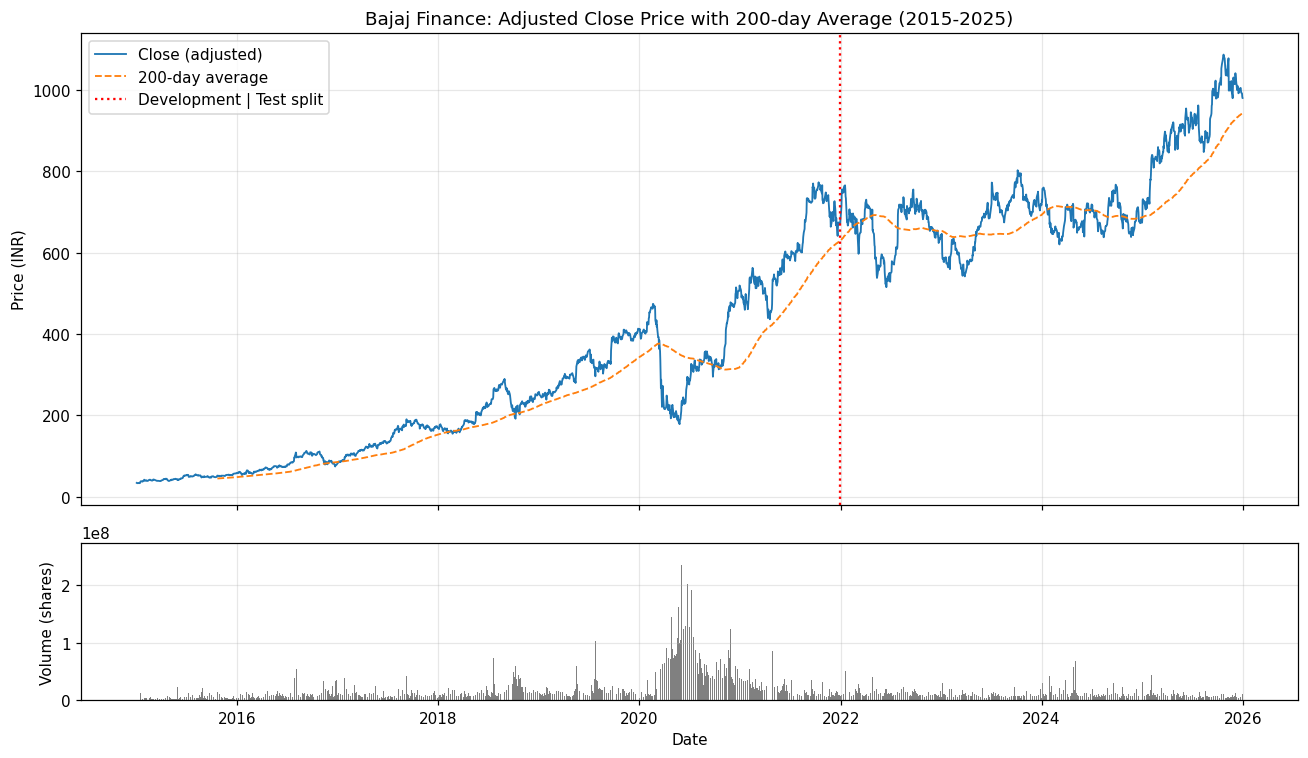

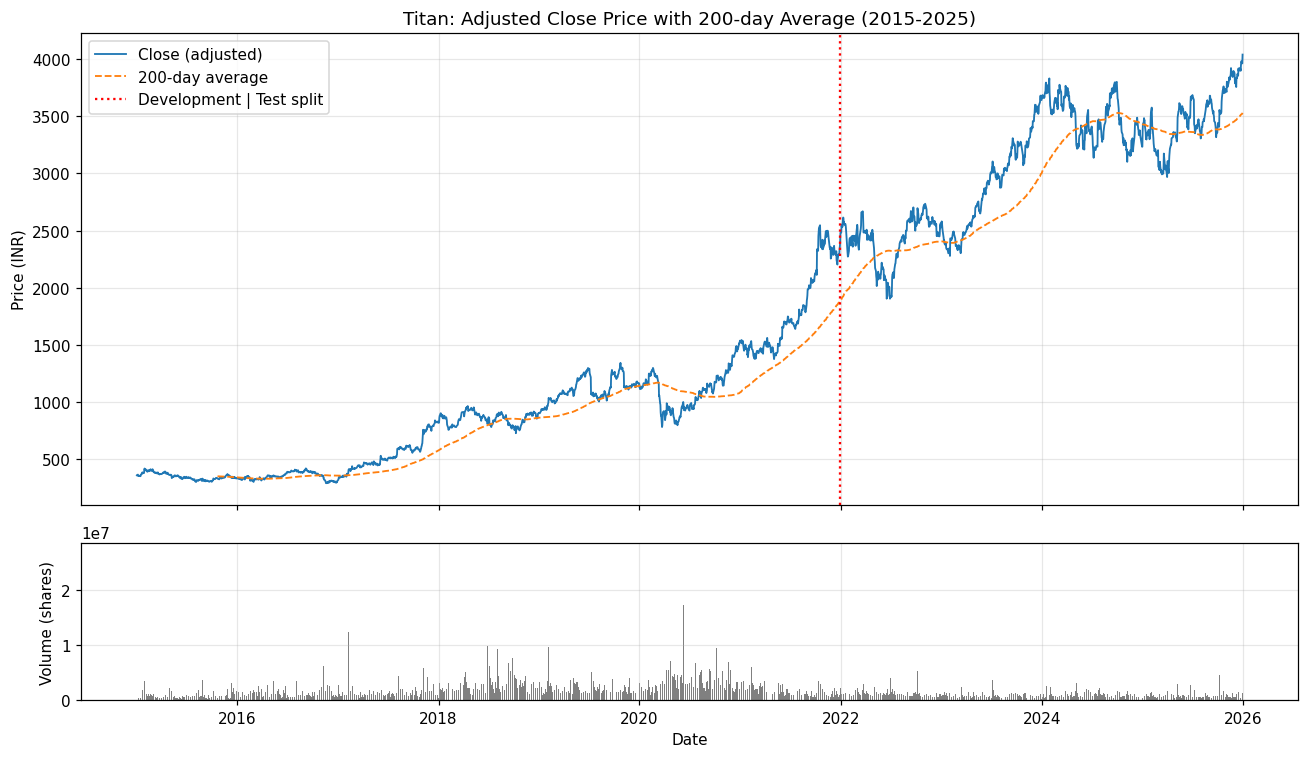

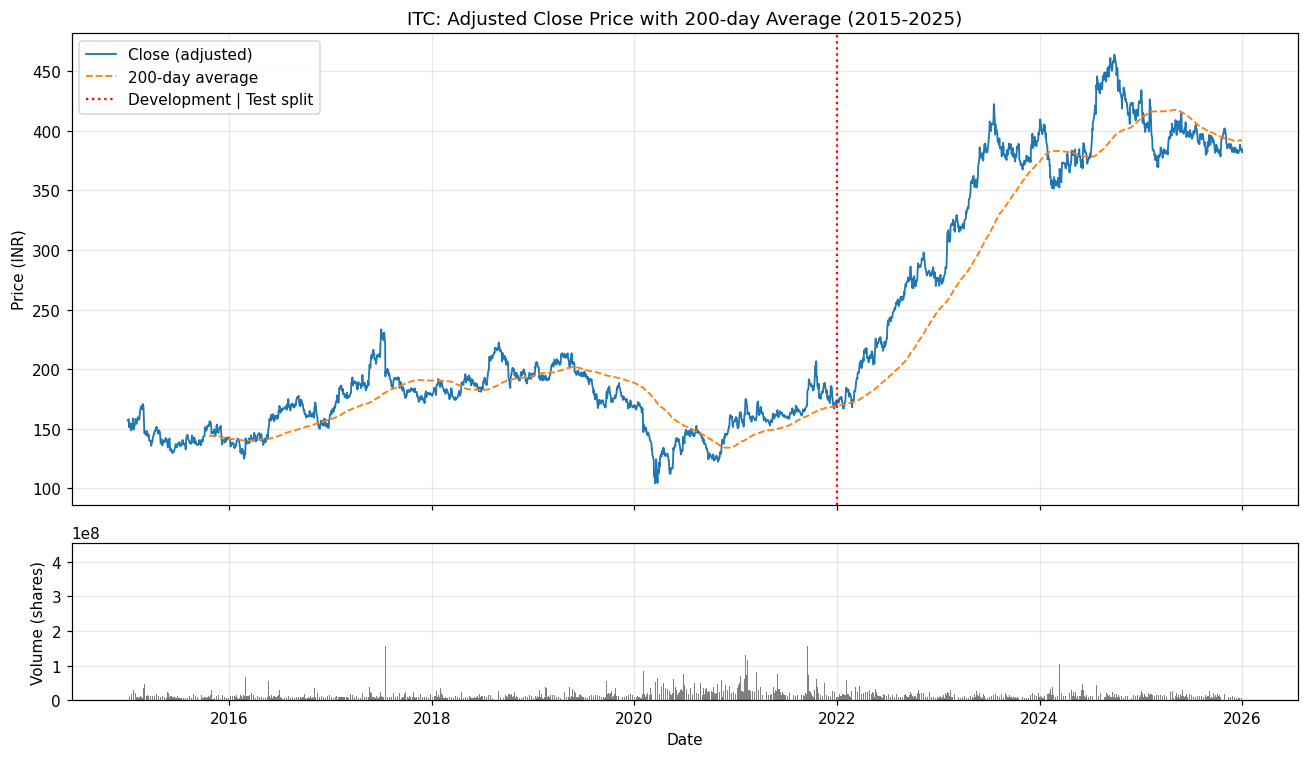

In [ ]:
for name, df in clean.items():
    sma200 = df["Close"].rolling(200).mean()

    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]}
    )
    ax1.plot(df.index, df["Close"], label="Close (adjusted)", lw=1.2)
    ax1.plot(df.index, sma200, label="200-day average", lw=1.2, ls="--")
    ax1.axvline(pd.Timestamp(DEV_END), color="red", ls=":", label="Development | Test split")
    ax1.set_title(f"{name}: Adjusted Close Price with 200-day Average (2015-2025)")
    ax1.set_ylabel("Price (INR)")
    ax1.legend(loc="upper left")

    ax2.bar(df.index, df["Volume"], width=1.0, color="grey")
    ax2.set_ylabel("Volume (shares)")
    ax2.set_xlabel("Date")

    fig.tight_layout()
    fig.savefig(os.path.join(PLOT_DIR, f"price_{name.replace(' ', '_').lower()}.png"), dpi=150)
    plt.show()

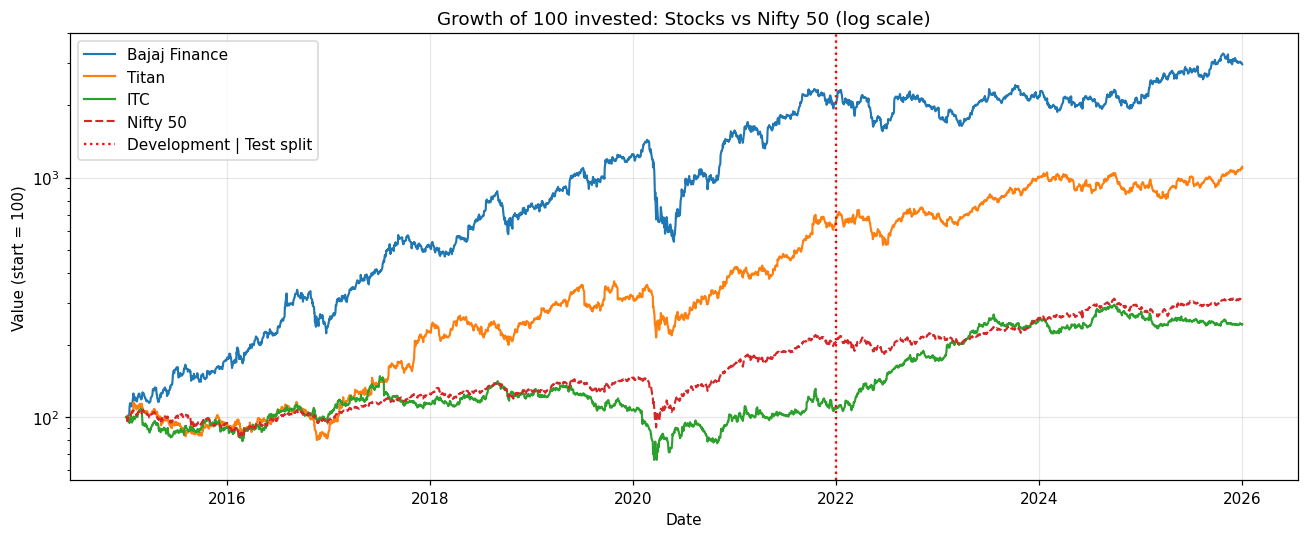

In [ ]:
common_start = max(df.index.min() for df in all_clean.values())

fig, ax = plt.subplots(figsize=(12, 5))
for name, df in all_clean.items():
    s = df["Close"][df.index >= common_start]
    ax.plot(s.index, 100 * s / s.iloc[0], label=name, lw=1.4,
            ls="--" if name == BENCHMARK_NAME else "-")
ax.axvline(pd.Timestamp(DEV_END), color="red", ls=":", label="Development | Test split")
ax.set_yscale("log")
ax.set_title("Growth of 100 invested: Stocks vs Nifty 50 (log scale)")
ax.set_xlabel("Date")
ax.set_ylabel("Value (start = 100)")
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "rebased_comparison.png"), dpi=150)
plt.show()

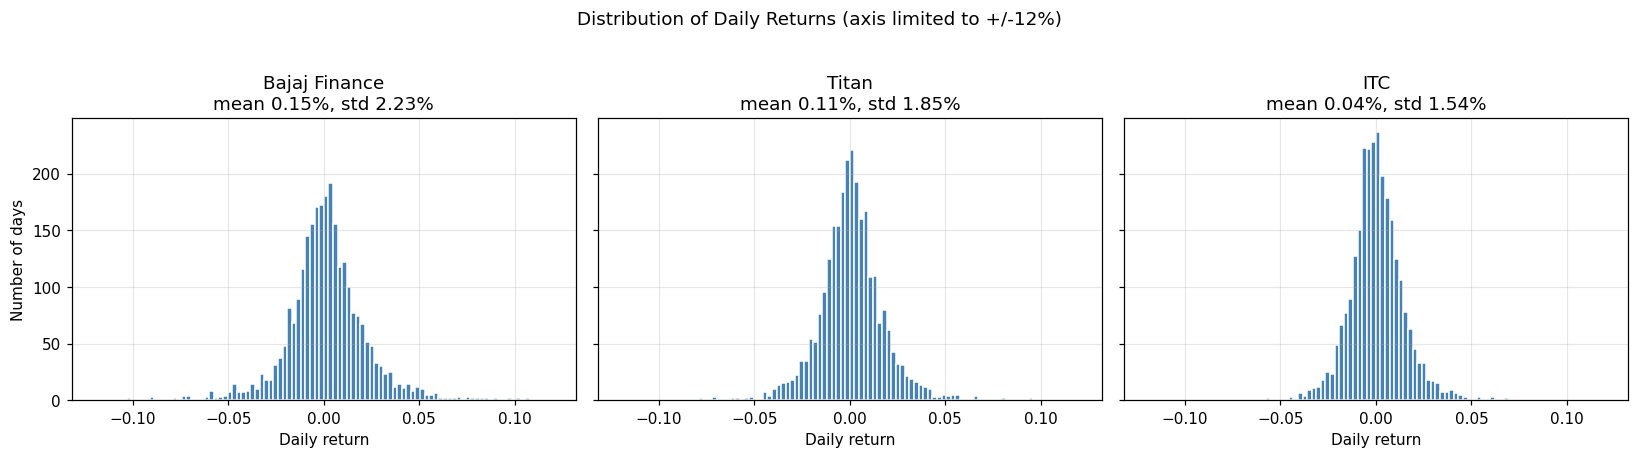

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, df) in zip(axes, clean.items()):
    r = df["Close"].pct_change().dropna()
    ax.hist(r, bins=100, range=(-0.12, 0.12), color="steelblue", edgecolor="white")
    ax.set_title(f"{name}\nmean {r.mean()*100:.2f}%, std {r.std()*100:.2f}%")
    ax.set_xlabel("Daily return")
axes[0].set_ylabel("Number of days")
fig.suptitle("Distribution of Daily Returns (axis limited to +/-12%)", y=1.03)
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "return_distribution.png"), dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
EMA_FAST = 20
EMA_SLOW = 50
ATR_N = 14
ADX_N = 14
ADX_MIN = 25   


def ema(series, n):
    return series.ewm(span=n, adjust=False, min_periods=n).mean()


def wilder(series, n):
    return series.ewm(alpha=1 / n, adjust=False, min_periods=n).mean()


def true_range(df):
    prev_close = df["Close"].shift(1)
    parts = pd.concat([
        df["High"] - df["Low"],
        (df["High"] - prev_close).abs(),
        (df["Low"] - prev_close).abs(),
    ], axis=1)
    return parts.max(axis=1, skipna=False)


def atr(df, n):
    return wilder(true_range(df), n)


def adx(df, n):
    up = df["High"].diff()
    down = -df["Low"].diff()
    plus_dm = pd.Series(np.where((up > down) & (up > 0), up, 0.0), index=df.index)
    minus_dm = pd.Series(np.where((down > up) & (down > 0), down, 0.0), index=df.index)
    plus_dm.iloc[0] = np.nan
    minus_dm.iloc[0] = np.nan

    atr_n = wilder(true_range(df), n)
    plus_di = 100 * wilder(plus_dm, n) / atr_n
    minus_di = 100 * wilder(minus_dm, n) / atr_n
    dx = 100 * (plus_di - minus_di).abs() / (plus_di + minus_di)
    return wilder(dx, n), plus_di, minus_di

In [ ]:
def add_signals(df, ema_fast=EMA_FAST, ema_slow=EMA_SLOW, atr_n=ATR_N, adx_n=ADX_N, adx_min=ADX_MIN):
    out = df.copy()
    out["EMA_fast"] = ema(out["Close"], ema_fast)
    out["EMA_slow"] = ema(out["Close"], ema_slow)
    out["ATR"] = atr(out, atr_n)
    out["ADX"], out["plus_DI"], out["minus_DI"] = adx(out, adx_n)

    valid = out["EMA_slow"].notna()
    out["trend_up"] = (out["EMA_fast"] > out["EMA_slow"]) & valid

    prev = out["trend_up"].shift(1, fill_value=False)
    out["crossover"] = 0
    out.loc[out["trend_up"] & ~prev, "crossover"] = 1
    out.loc[~out["trend_up"] & prev, "crossover"] = -1

    out["trend_up_adx"] = out["trend_up"] & (out["ADX"] > adx_min)

    out["target_basic"] = out["trend_up"].shift(1, fill_value=False).astype(int)
    out["target_adx"] = out["trend_up_adx"].shift(1, fill_value=False).astype(int)
    return out


sig = {name: add_signals(df) for name, df in clean.items()}
display(sig[list(sig)[0]].tail(5).round(2))

Price,Open,High,Low,Close,Volume,EMA_fast,EMA_slow,ATR,ADX,plus_DI,minus_DI,trend_up,crossover,trend_up_adx,target_basic,target_adx
Date,,,,,,,,,,,,,,,,
2025-12-24,1004.82,1031.06,999.85,1005.52,5984816,1007.47,1008.32,18.95,9.97,23.98,16.48,False,0,False,0,0
2025-12-26,1005.52,1005.52,991.90,993.89,5211460,1006.17,1007.76,18.57,9.96,22.72,18.68,False,0,False,0,0
2025-12-29,996.87,997.77,983.55,991.90,6715489,1004.82,1007.13,18.26,9.34,21.46,20.90,False,0,False,0,0
2025-12-30,988.03,991.50,981.07,983.26,7473887,1002.76,1006.20,17.73,8.75,20.52,20.99,False,0,False,0,0
2025-12-31,983.95,988.13,972.42,980.77,9895270,1000.67,1005.20,17.58,8.80,19.21,23.17,False,0,False,0,0


In [ ]:
rows = []
for name, df in sig.items():
    rows.append({
        "Stock": name,
        "First day with signals": df["EMA_slow"].first_valid_index().date(),
        "Buy crossovers": int((df["crossover"] == 1).sum()),
        "Sell crossovers": int((df["crossover"] == -1).sum()),
        "% days basic target = 1": round(100 * df["target_basic"].mean(), 1),
        "% days ADX-filtered target = 1": round(100 * df["target_adx"].mean(), 1),
        "Median ADX": round(df["ADX"].median(), 1),
        "ADX in [0,100]": bool(df["ADX"].dropna().between(0, 100).all()),
    })
display(pd.DataFrame(rows).set_index("Stock"))


def causality_test(df, cutoff):
    truncated = add_signals(df.loc[:cutoff])
    full = add_signals(df)
    cols = ["EMA_fast", "EMA_slow", "ATR", "ADX", "target_basic", "target_adx"]
    a = truncated.loc[cutoff, cols].astype(float)
    b = full.loc[cutoff, cols].astype(float)
    return np.allclose(a.values, b.values, equal_nan=True)


for name, df in clean.items():
    for cutoff in [df.index[len(df) // 3], df.index[len(df) // 2], df.index[-300]]:
        assert causality_test(df, cutoff), f"Look-ahead detected in {name} at {cutoff}"
    d = sig[name]
    assert (d["target_basic"].iloc[1:] == d["trend_up"].astype(int).shift(1).iloc[1:]).all()
print("All look-ahead checks passed.")

,First day with signals,Buy crossovers,Sell crossovers,% days basic target = 1,% days ADX-filtered target = 1,Median ADX,"ADX in [0,100]"
Stock,,,,,,,
Bajaj Finance,2015-03-16,22,22,68.7,35.8,26.2,True
Titan,2015-03-16,23,22,65.9,39.0,25.8,True
ITC,2015-03-16,23,23,53.6,22.8,22.1,True


All look-ahead checks passed.


In [ ]:
INITIAL_CAPITAL = 1_000_000  
COST_PER_SIDE = 0.0010     
SLIPPAGE_PER_SIDE = 0.0005 
ATR_STOP_MULT = 3.0             

STRATEGIES = {"Basic": "target_basic", "ADX-filtered": "target_adx"}
PERIODS = {"Development": ("2015-01-01", DEV_END)} 

In [ ]:
def _window(df, start, end):
    """Row positions of the first and last day of the period (never row 0, we need a previous day)."""
    i_start = max(df.index.searchsorted(pd.Timestamp(start), side="left"), 1)
    i_end = df.index.searchsorted(pd.Timestamp(end), side="right") - 1
    return i_start, i_end


def backtest(df, target_col, start, end, capital=INITIAL_CAPITAL, cost=COST_PER_SIDE,
             slip=SLIPPAGE_PER_SIDE, atr_mult=ATR_STOP_MULT):
    """Run one long-only backtest. Returns dict with equity curve, trade log and invested flag."""
    idx = df.index
    O = df["Open"].to_numpy(float)
    H = df["High"].to_numpy(float)
    L = df["Low"].to_numpy(float)
    C = df["Close"].to_numpy(float)
    ATR = df["ATR"].to_numpy(float)
    T = df[target_col].to_numpy(int)     
    i_start, i_end = _window(df, start, end)

    cash, shares = float(capital), 0
    entry_i, entry_raw, entry_px, entry_fee = None, 0.0, 0.0, 0.0
    highest, blocked = np.nan, False
    trades, equity, invested = [], [], []

    def close_position(i, raw_price, reason):
        nonlocal cash, shares
        sell_px = raw_price * (1 - slip)  
        proceeds = shares * sell_px
        fee = proceeds * cost
        cash += proceeds - fee
        cost_basis = shares * entry_px + entry_fee
        net_pnl = proceeds - fee - cost_basis
        trades.append({
            "Entry date": idx[entry_i], "Exit date": idx[i],
            "Entry price": entry_px, "Exit price": sell_px, "Shares": shares,
            "Net P&L (INR)": net_pnl, "Return (%)": 100 * net_pnl / cost_basis,
            "Fees (INR)": entry_fee + fee,
            "Slippage (INR)": shares * entry_raw * slip + shares * raw_price * slip,
            "Holding days": (idx[i] - idx[entry_i]).days, "Exit reason": reason,
        })
        shares = 0

    for i in range(i_start, i_end + 1):
        if T[i] == 0:
            blocked = False                       

        # 1) signal exit at today's open
        if shares > 0 and T[i] == 0:
            close_position(i, O[i], "signal")

        # 2) entry at today's open
        if shares == 0 and T[i] == 1 and not blocked:
            buy_px = O[i] * (1 + slip)           
            n = int(cash // (buy_px * (1 + cost)))
            if n > 0:
                fee = n * buy_px * cost
                cash -= n * buy_px + fee
                shares, entry_i, entry_raw, entry_px, entry_fee = n, i, O[i], buy_px, fee
                highest = C[i - 1]              

        # 3) trailing stop, checked against today's low
        if shares > 0 and atr_mult is not None and not np.isnan(ATR[i - 1]):
            stop_level = highest - atr_mult * ATR[i - 1]
            if L[i] <= stop_level:
                close_position(i, min(O[i], stop_level), "stop") 
                blocked = True

        # 4) end of day
        if shares > 0:
            highest = max(highest, C[i])
        equity.append(cash + shares * C[i])
        invested.append(shares > 0)

    if shares > 0:
        close_position(i_end, C[i_end], "end of period")
        equity[-1] = cash
        invested[-1] = False

    dates = idx[i_start:i_end + 1]
    return {
        "equity": pd.Series(equity, index=dates, name="equity"),
        "trades": pd.DataFrame(trades),
        "invested": pd.Series(invested, index=dates),
    }


def buy_and_hold(df, start, end, capital=INITIAL_CAPITAL, cost=COST_PER_SIDE, slip=SLIPPAGE_PER_SIDE):
    """Buy at the first Open, sell at the last Close, same costs as the strategy."""
    i_start, i_end = _window(df, start, end)
    O, C = df["Open"].to_numpy(float), df["Close"].to_numpy(float)
    buy_px = O[i_start] * (1 + slip)
    n = int(capital // (buy_px * (1 + cost)))
    cash = capital - n * buy_px * (1 + cost)
    eq = cash + n * C[i_start:i_end + 1]
    sell_proceeds = n * C[i_end] * (1 - slip)
    eq[-1] = cash + sell_proceeds * (1 - cost)
    return pd.Series(eq, index=df.index[i_start:i_end + 1], name="buy_and_hold")


def nifty_benchmark(nifty_df, dates, capital=INITIAL_CAPITAL):
    """Nifty rebased to the same starting capital on the same dates (no costs: an index cannot be bought directly)."""
    close = nifty_df["Close"].reindex(dates).ffill().bfill()
    first_open = nifty_df["Open"].reindex(dates).bfill().iloc[0]
    return (capital * close / first_open).rename("nifty")


def max_drawdown_pct(eq):
    return float((eq / eq.cummax() - 1).min() * 100)

In [ ]:
dates8 = pd.bdate_range("2020-01-01", periods=8)
toy = pd.DataFrame({
    "Open":  [100, 100, 102, 104, 108, 103, 101, 100],
    "High":  [101, 103, 105, 109, 110, 104, 102, 101],
    "Low":   [ 99,  99, 101, 103, 102, 100,  99,  98],
    "Close": [100, 102, 104, 108, 103, 101, 100,  99],
    "ATR":   [  2,   2,   2,   2,   2,   2,   2,   2],
    "T":     [  0,   1,   1,   1,   1,   0,   0,   0],
}, index=dates8, dtype=float)
toy["T"] = toy["T"].astype(int)

# Test A: no costs, no stop. Buy at Open on day 2 (100), sell at Open on day 6 (103): 10 shares, profit 30.
a = backtest(toy, "T", "2020-01-01", "2020-01-10", capital=1000, cost=0, slip=0, atr_mult=None)
assert abs(a["equity"].iloc[-1] - 1030) < 1e-9
assert a["trades"].iloc[0]["Exit reason"] == "signal"

# Test B: stop of 3 ATR. Highest close before day 5 is 108, stop = 108 - 6 = 102, day 5 Low is 102, so we sell at 102.
b = backtest(toy, "T", "2020-01-01", "2020-01-10", capital=1000, cost=0, slip=0, atr_mult=3.0)
assert abs(b["equity"].iloc[-1] - 1020) < 1e-9
assert b["trades"].iloc[0]["Exit reason"] == "stop"
assert abs(b["trades"].iloc[0]["Exit price"] - 102) < 1e-9

# Test C: with 0.10% cost and 0.05% slippage per side, 9 shares fit and the result is about 1024.26.
c = backtest(toy, "T", "2020-01-01", "2020-01-10", capital=1000, cost=0.001, slip=0.0005, atr_mult=None)
assert c["trades"].iloc[0]["Shares"] == 9
assert abs(c["equity"].iloc[-1] - 1024.2595) < 0.01

print("Toy examples passed: entries, exits, stop and costs behave as the rules say.")

Toy examples passed: entries, exits, stop and costs behave as the rules say.


In [ ]:
from itertools import product

RF_ANNUAL = 0.06        # risk-free rate assumption (approx. Indian 91-day T-bill yield). State it in the report.
TRADING_DAYS = 252      # annualisation factor: Sharpe/Sortino use DAILY returns x sqrt(252)
DEV_START = PERIODS["Development"][0]
TEST_START = (pd.Timestamp(DEV_END) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")


def with_start(eq, capital=INITIAL_CAPITAL):
    """Prepend the starting capital so the first day's return and cumulative return are measured from INR 10 lakh."""
    first = pd.Series([float(capital)], index=[eq.index[0] - pd.Timedelta(days=1)])
    return pd.concat([first, eq.astype(float)])


def equity_metrics(eq, rf=RF_ANNUAL):
    """Return/risk metrics from a daily equity curve that already includes the starting capital."""
    r = eq.pct_change().dropna()
    years = (eq.index[-1] - eq.index[0]).days / 365.25
    cum = eq.iloc[-1] / eq.iloc[0] - 1
    ann = (1 + cum) ** (1 / years) - 1 if years > 0 and cum > -1 else np.nan

    rf_daily = (1 + rf) ** (1 / TRADING_DAYS) - 1
    ex = r - rf_daily
    sd = ex.std(ddof=1)
    sharpe = ex.mean() / sd * np.sqrt(TRADING_DAYS) if sd > 0 else np.nan
    downside = np.sqrt((np.minimum(ex, 0.0) ** 2).mean())
    sortino = ex.mean() / downside * np.sqrt(TRADING_DAYS) if downside > 0 else np.nan
    return {
        "Cumulative return (%)": 100 * cum,
        "Annualised return (%)": 100 * ann,
        "Sharpe": sharpe,
        "Sortino": sortino,
        "Max drawdown (%)": max_drawdown_pct(eq),
    }


def trade_metrics(tr):
    """Statistics from the trade log. Undefined values are NaN and are shown as N/A."""
    keys = ["Trades", "Win rate (%)", "Profit factor", "Avg profit (INR)", "Avg loss (INR)",
            "Max profit (INR)", "Max loss (INR)", "Avg win (%)", "Avg loss (%)",
            "Best trade (%)", "Worst trade (%)"]
    if len(tr) == 0:
        return {k: (0 if k == "Trades" else np.nan) for k in keys}
    pnl, ret = tr["Net P&L (INR)"], tr["Return (%)"]
    wins, losses = pnl[pnl > 0], pnl[pnl < 0]
    return {
        "Trades": len(tr),
        "Win rate (%)": 100 * (pnl > 0).mean(),
        "Profit factor": wins.sum() / abs(losses.sum()) if len(losses) else np.nan,   # N/A if no losing trade
        "Avg profit (INR)": wins.mean() if len(wins) else np.nan,                      # N/A if no winning trade
        "Avg loss (INR)": losses.mean() if len(losses) else np.nan,
        "Max profit (INR)": wins.max() if len(wins) else np.nan,
        "Max loss (INR)": losses.min() if len(losses) else np.nan,
        "Avg win (%)": ret[pnl > 0].mean() if len(wins) else np.nan,
        "Avg loss (%)": ret[pnl < 0].mean() if len(losses) else np.nan,
        "Best trade (%)": ret.max(),
        "Worst trade (%)": ret.min(),
    }


def show_na(df, digits=2):
    """Display helper: round numbers and print NaN as N/A."""
    out = df.round(digits).astype(object)
    return out.where(df.notna(), "N/A")

Development-period Sharpe (mean of the 3 stocks); columns = ADX threshold:


,Basic,15,20,25,30,35
EMA fast/slow,,,,,,
10/50,0.25,0.31,0.20,-0.06,-0.25,-0.57
10/100,-0.03,0.12,0.14,0.01,-0.21,-0.60
10/150,-0.15,0.06,0.27,0.12,-0.05,-0.58
20/50,0.11,0.21,0.14,-0.03,-0.26,-0.60
20/100,-0.28,0.09,0.10,-0.02,-0.12,-0.60
20/150,-0.26,0.05,0.23,0.07,-0.02,-0.53
30/50,-0.21,0.13,0.05,-0.11,-0.26,-0.63
30/100,-0.51,0.01,0.15,0.04,-0.07,-0.58
30/150,-0.51,-0.04,0.18,0.01,-0.13,-0.52



Top 5 settings by neighbourhood-smoothed Sharpe:
  EMA 10/50, ADX > 15:  own Sharpe 0.31, smoothed 0.16
  EMA 10/100, ADX > 15:  own Sharpe 0.12, smoothed 0.16
  EMA 20/50, ADX > 15:  own Sharpe 0.21, smoothed 0.14
  EMA 10/150, ADX > 15:  own Sharpe 0.06, smoothed 0.13
  EMA 20/100, ADX > 15:  own Sharpe 0.09, smoothed 0.13

SELECTED (development data only): EMA 10/50, ADX > 15


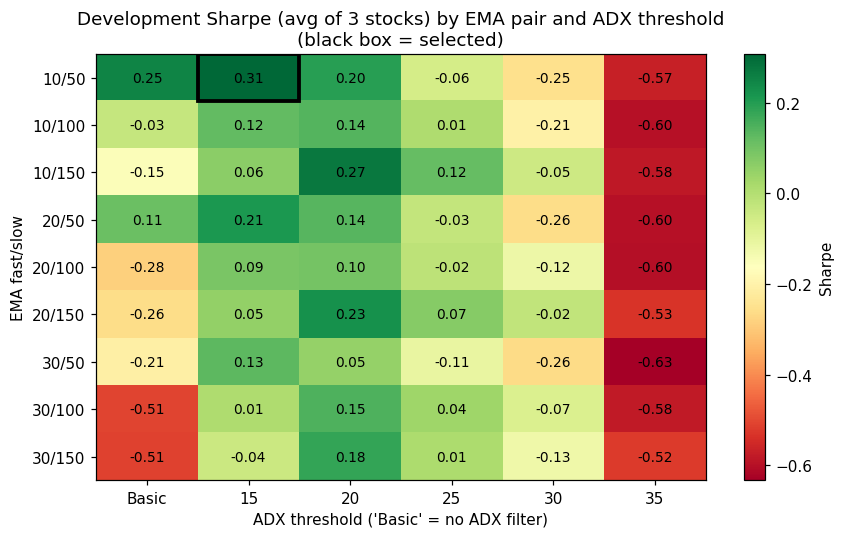

In [ ]:
FAST_GRID = [10, 20, 30]
SLOW_GRID = [50, 100, 150]
ADX_GRID = [15, 20, 25, 30, 35]
PAIRS = list(product(FAST_GRID, SLOW_GRID))
COLS = ["Basic"] + ADX_GRID

dev_s, dev_e = DEV_START, DEV_END
sh = {}   # (fast, slow, column, stock) -> development Sharpe

for fast, slow in PAIRS:
    for stock, base in clean.items():
        d0 = add_signals(base, ema_fast=fast, ema_slow=slow)
        r0 = backtest(d0, "target_basic", dev_s, dev_e)
        sh[(fast, slow, "Basic", stock)] = equity_metrics(with_start(r0["equity"]))["Sharpe"]
        for a in ADX_GRID:
            d = add_signals(base, ema_fast=fast, ema_slow=slow, adx_min=a)
            r = backtest(d, "target_adx", dev_s, dev_e)
            sh[(fast, slow, a, stock)] = equity_metrics(with_start(r["equity"]))["Sharpe"]

# Mean Sharpe across the three stocks for every setting
grid_mean = pd.DataFrame(
    {c: [np.nanmean([sh[(f, s, c, st)] for st in clean]) for f, s in PAIRS] for c in COLS},
    index=[f"{f}/{s}" for f, s in PAIRS],
)
grid_mean.index.name = "EMA fast/slow"
print("Development-period Sharpe (mean of the 3 stocks); columns = ADX threshold:")
display(grid_mean.round(2))

# Neighbourhood-smoothed score: average each ADX-filtered setting with its neighbours (+/-1 step in
# fast, slow and ADX). This rewards a stable plateau over a single lucky spike.
nf, ns, na = len(FAST_GRID), len(SLOW_GRID), len(ADX_GRID)
S = np.array([[[grid_mean.loc[f"{f}/{s}", a] for a in ADX_GRID] for s in SLOW_GRID] for f in FAST_GRID])
smooth = np.full_like(S, np.nan)
for i, j, k in product(range(nf), range(ns), range(na)):
    smooth[i, j, k] = np.nanmean(S[max(i-1, 0):i+2, max(j-1, 0):j+2, max(k-1, 0):k+2])

order = np.dstack(np.unravel_index(np.argsort(-np.nan_to_num(smooth, nan=-9).ravel()), smooth.shape))[0]
print("\nTop 5 settings by neighbourhood-smoothed Sharpe:")
for i, j, k in order[:5]:
    print(f"  EMA {FAST_GRID[i]}/{SLOW_GRID[j]}, ADX > {ADX_GRID[k]}:  own Sharpe {S[i,j,k]:.2f}, smoothed {smooth[i,j,k]:.2f}")

bi, bj, bk = order[0]
EMA_FAST_F, EMA_SLOW_F, ADX_MIN_F = FAST_GRID[bi], SLOW_GRID[bj], ADX_GRID[bk]
print(f"\nSELECTED (development data only): EMA {EMA_FAST_F}/{EMA_SLOW_F}, ADX > {ADX_MIN_F}")

# Heatmap of the grid with the chosen cell outlined
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(grid_mean.values, cmap="RdYlGn", aspect="auto")
ax.set_xticks(range(len(COLS)))
ax.set_xticklabels([str(c) for c in COLS])
ax.set_yticks(range(len(grid_mean)))
ax.set_yticklabels(grid_mean.index)
for (y, x), v in np.ndenumerate(grid_mean.values):
    ax.text(x, y, f"{v:.2f}", ha="center", va="center", fontsize=9)
sel_y = PAIRS.index((EMA_FAST_F, EMA_SLOW_F)); sel_x = COLS.index(ADX_MIN_F)
ax.add_patch(plt.Rectangle((sel_x - 0.5, sel_y - 0.5), 1, 1, fill=False, edgecolor="black", lw=2.5))
ax.set_title("Development Sharpe (avg of 3 stocks) by EMA pair and ADX threshold\n(black box = selected)")
ax.set_xlabel("ADX threshold ('Basic' = no ADX filter)")
ax.set_ylabel("EMA fast/slow")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Sharpe")
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "parameter_heatmap.png"), dpi=150)
plt.show()

In [ ]:
print("Neighbourhood of the selected setting (mean Sharpe over the 3 stocks):")
nb = S[max(bi-1, 0):bi+2, max(bj-1, 0):bj+2, max(bk-1, 0):bk+2]
print(f"  {nb.size} neighbouring settings: mean {np.nanmean(nb):.2f}, min {np.nanmin(nb):.2f}, max {np.nanmax(nb):.2f}")
print(f"  Share of ALL {S.size} grid settings with positive Sharpe: {100*np.mean(S > 0):.0f}%")

rows = []
for stock in clean:
    all_cells = [sh[(f, s, a, stock)] for f, s in PAIRS for a in ADX_GRID]
    bh_sharpe = equity_metrics(with_start(buy_and_hold(clean[stock], dev_s, dev_e)))["Sharpe"]
    rows.append({
        "Stock": stock,
        "Sharpe, selected setting": sh[(EMA_FAST_F, EMA_SLOW_F, ADX_MIN_F, stock)],
        "Sharpe, same EMA, no ADX filter": sh[(EMA_FAST_F, EMA_SLOW_F, "Basic", stock)],
        "Median Sharpe over grid": np.nanmedian(all_cells),
        "% grid settings with Sharpe > 0": 100 * np.mean(np.array(all_cells) > 0),
        "Buy & hold Sharpe": bh_sharpe,
    })
robust = pd.DataFrame(rows).set_index("Stock")
display(robust.round(2))

# Does the ADX filter help at the selected EMA pair? (development Sharpe, mean of 3 stocks)
basic_mean = grid_mean.loc[f"{EMA_FAST_F}/{EMA_SLOW_F}", "Basic"]
adx_mean = grid_mean.loc[f"{EMA_FAST_F}/{EMA_SLOW_F}", ADX_MIN_F]
FINAL_STRATEGY = "ADX-filtered" if adx_mean >= basic_mean else "Basic"
print(f"\nAt EMA {EMA_FAST_F}/{EMA_SLOW_F}: Basic Sharpe {basic_mean:.2f} vs ADX-filtered {adx_mean:.2f} -> "
      f"strategy used for trade charts: {FINAL_STRATEGY}")

Neighbourhood of the selected setting (mean Sharpe over the 3 stocks):
  8 neighbouring settings: mean 0.16, min 0.09, max 0.31
  Share of ALL 45 grid settings with positive Sharpe: 49%


,"Sharpe, selected setting","Sharpe, same EMA, no ADX filter",Median Sharpe over grid,% grid settings with Sharpe > 0,Buy & hold Sharpe
Stock,,,,,
Bajaj Finance,0.95,0.79,0.30,73.33,1.17
Titan,0.18,0.26,0.14,64.44,0.84
ITC,-0.21,-0.30,-0.54,0.00,-0.03



At EMA 10/50: Basic Sharpe 0.25 vs ADX-filtered 0.31 -> strategy used for trade charts: ADX-filtered


In [ ]:
sig_final = {n: add_signals(df, ema_fast=EMA_FAST_F, ema_slow=EMA_SLOW_F, adx_min=ADX_MIN_F)
             for n, df in clean.items()}

# Look-ahead check again, with the final parameters
cols_chk = ["EMA_fast", "EMA_slow", "ATR", "ADX", "target_basic", "target_adx"]
for n, df in clean.items():
    for cutoff in [df.index[len(df) // 3], df.index[len(df) // 2], df.index[-300]]:
        a = add_signals(df.loc[:cutoff], ema_fast=EMA_FAST_F, ema_slow=EMA_SLOW_F, adx_min=ADX_MIN_F).loc[cutoff, cols_chk].astype(float)
        b = sig_final[n].loc[cutoff, cols_chk].astype(float)
        assert np.allclose(a.values, b.values, equal_nan=True), f"Look-ahead in {n} at {cutoff}"

PERIODS_FINAL = {"Development": (DEV_START, DEV_END), "Test": (TEST_START, END)}
res_f, bh_f, nifty_f = {}, {}, {}
for pname, (s, e) in PERIODS_FINAL.items():
    for stock, df in sig_final.items():
        bh_f[(pname, stock)] = buy_and_hold(df, s, e)
        nifty_f[(pname, stock)] = nifty_benchmark(nifty, bh_f[(pname, stock)].index)
        for sname, col in STRATEGIES.items():
            res_f[(pname, stock, sname)] = backtest(df, col, s, e)

# Sanity checks (same ideas as before, plus: trades must stay inside their period)
for (pname, stock, sname), r in res_f.items():
    eq, tr = r["equity"], r["trades"]
    s, e = PERIODS_FINAL[pname]
    if len(tr):
        assert abs(eq.iloc[-1] - (INITIAL_CAPITAL + tr["Net P&L (INR)"].sum())) < 1e-6 * INITIAL_CAPITAL
        assert (tr["Exit date"] >= tr["Entry date"]).all()
        assert (tr["Entry date"].iloc[1:].values > tr["Exit date"].iloc[:-1].values).all()
        assert tr["Entry date"].min() >= pd.Timestamp(s) and tr["Exit date"].max() <= pd.Timestamp(e)
print("Final-run sanity checks passed.")
print(f"Test period: {TEST_START} to {END}. Positions start flat at the beginning of each period.")

Final-run sanity checks passed.
Test period: 2022-01-01 to 2026-01-01. Positions start flat at the beginning of each period.


In [ ]:
for (pname, stock, sname), r in res_f.items():
    eq, tr, inv = r["equity"], r["trades"], r["invested"]
    df = sig_final[stock]
    col = STRATEGIES[sname]
    tag = f"{pname} / {stock} / {sname}"

    if len(tr):
        # 1) reconciliation
        assert abs(eq.iloc[-1] - (INITIAL_CAPITAL + tr["Net P&L (INR)"].sum())) < 1e-6 * INITIAL_CAPITAL, f"Reconciliation failed: {tag}"
        # 2) order of trades
        assert (tr["Exit date"] >= tr["Entry date"]).all(), f"Exit before entry: {tag}"
        assert (tr["Entry date"].iloc[1:].values > tr["Exit date"].iloc[:-1].values).all(), f"Overlapping trades: {tag}"
        # 3) execution at the open, on a day the signal was on
        for _, t in tr.iterrows():
            row = df.loc[t["Entry date"]]
            assert np.isclose(t["Entry price"], row["Open"] * (1 + SLIPPAGE_PER_SIDE)), f"Entry not at open: {tag}"
            assert row[col] == 1, f"Entry on a day the signal was off: {tag}"
    else:
        assert abs(eq.iloc[-1] - INITIAL_CAPITAL) < 1e-9

    # 4) flat days: equity unchanged when flat today and flat yesterday
    flat_both = (~inv) & (~inv.shift(1, fill_value=False))
    changes = eq.diff().abs()[flat_both].fillna(0)
    assert (changes < 1e-6).all(), f"Equity moved while flat: {tag}"

    # 5) costs should hurt, not help
    s, e = PERIODS_FINAL[pname]
    free = backtest(df, col, s, e, cost=0.0, slip=0.0)
    assert free["equity"].iloc[-1] >= eq.iloc[-1] - 1e-6, f"Zero-cost result is worse than with costs: {tag}"

print("All sanity checks passed for every stock and strategy.")

All sanity checks passed for every stock and strategy.


In [ ]:
rows = []
for pname in PERIODS_FINAL:
    for stock in sig_final:
        nifty_cum = 100 * (nifty_f[(pname, stock)].iloc[-1] / INITIAL_CAPITAL - 1)
        entries = [(sname, res_f[(pname, stock, sname)]["equity"], res_f[(pname, stock, sname)]["trades"])
                   for sname in STRATEGIES]
        entries.append(("Buy & hold", bh_f[(pname, stock)], None))
        entries.append(("Nifty 50 (no costs)", nifty_f[(pname, stock)], None))
        for label, eq, tr in entries:
            m = equity_metrics(with_start(eq))
            t = trade_metrics(tr) if tr is not None else {k: np.nan for k in trade_metrics(pd.DataFrame()).keys()}
            row = {"Period": pname, "Stock": stock, "Strategy": label, **m, **t,
                   "Nifty return (%)": nifty_cum,
                   "Excess vs Nifty (pp)": m["Cumulative return (%)"] - nifty_cum}
            rows.append(row)

metrics = pd.DataFrame(rows).set_index(["Period", "Stock", "Strategy"])
metrics.to_csv(os.path.join(DATA_DIR, "performance_metrics.csv"))

main_cols = ["Cumulative return (%)", "Annualised return (%)", "Sharpe", "Sortino", "Max drawdown (%)",
             "Trades", "Win rate (%)", "Profit factor", "Nifty return (%)", "Excess vs Nifty (pp)"]
trade_cols = ["Avg profit (INR)", "Avg loss (INR)", "Max profit (INR)", "Max loss (INR)",
              "Avg win (%)", "Avg loss (%)", "Best trade (%)", "Worst trade (%)"]

for pname, (s, e) in PERIODS_FINAL.items():
    print("=" * 100)
    print(f"{pname.upper()} PERIOD ({s} to {e}) | INR {INITIAL_CAPITAL:,} per stock | "
          f"costs {COST_PER_SIDE*100:.2f}% + slippage {SLIPPAGE_PER_SIDE*100:.2f}% per side | "
          f"Sharpe/Sortino: daily returns, rf = {RF_ANNUAL*100:.1f}% p.a., x sqrt({TRADING_DAYS})")
    print("=" * 100)
    display(show_na(metrics.loc[pname, main_cols]))
    print("Per-trade statistics (strategies only; N/A = undefined, e.g. no losing trade):")
    display(show_na(metrics.loc[pname, trade_cols].dropna(how="all")))

# Trade log for both periods
logs = []
for (pname, stock, sname), r in res_f.items():
    if len(r["trades"]):
        t = r["trades"].copy()
        t.insert(0, "Strategy", sname); t.insert(0, "Stock", stock); t.insert(0, "Period", pname)
        logs.append(t)
trade_log_final = pd.concat(logs, ignore_index=True)
trade_log_final.to_csv(os.path.join(DATA_DIR, "trade_log_final.csv"), index=False)
print("Saved trade_log_final.csv with", len(trade_log_final), "trades")

DEVELOPMENT PERIOD (2015-01-01 to 2021-12-31) | INR 1,000,000 per stock | costs 0.10% + slippage 0.05% per side | Sharpe/Sortino: daily returns, rf = 6.0% p.a., x sqrt(252)


Cumulative return (%) Annualised return (%)  \
Stock         Strategy                                                          
Bajaj Finance Basic                              249.75                 19.59   
              ADX-filtered                       402.68                 25.95   
              Buy & hold                        1927.39                 53.73   
              Nifty 50 (no costs)                109.37                 11.14   
Titan         Basic                               85.31                  9.22   
              ADX-filtered                        67.22                  7.62   
              Buy & hold                         584.17                 31.63   
              Nifty 50 (no costs)                109.37                 11.14   
ITC           Basic                                9.29                  1.28   
              ADX-filtered                        14.23                  1.92   
              Buy & hold                           9.04                  1.24   
              Nifty 50 (no costs)                109.37                 11.14   

                                  Sharpe Sortino Max drawdown (%) Trades  \
Stock         Strategy                                                     
Bajaj Finance Basic                 0.79    1.43           -15.88   12.0   
              ADX-filtered          0.95    1.64           -19.15   26.0   
              Buy & hold            1.17    1.73           -62.44    N/A   
              Nifty 50 (no costs)   0.37     0.5           -38.44    N/A   
Titan         Basic                 0.26    0.46           -23.95   17.0   
              ADX-filtered          0.18    0.31           -25.56   18.0   
              Buy & hold            0.84    1.31           -41.73    N/A   
              Nifty 50 (no costs)   0.37     0.5           -38.44    N/A   
ITC           Basic                 -0.3   -0.44           -20.14   20.0   
              ADX-filtered         -0.21    -0.3           -24.84   27.0   
              Buy & hold           -0.03   -0.04           -55.28    N/A   
              Nifty 50 (no costs)   0.37     0.5           -38.44    N/A   

                                  Win rate (%) Profit factor Nifty return (%)  \
Stock         Strategy                                                          
Bajaj Finance Basic                      66.67         12.96           109.37   
              ADX-filtered               57.69          7.33           109.37   
              Buy & hold                   N/A           N/A           109.37   
              Nifty 50 (no costs)          N/A           N/A           109.37   
Titan         Basic                      58.82           2.4           109.37   
              ADX-filtered               55.56          2.08           109.37   
              Buy & hold                   N/A           N/A           109.37   
              Nifty 50 (no costs)          N/A           N/A           109.37   
ITC           Basic                       30.0          1.23           109.37   
              ADX-filtered               40.74          1.36           109.37   
              Buy & hold                   N/A           N/A           109.37   
              Nifty 50 (no costs)          N/A           N/A           109.37   

                                  Excess vs Nifty (pp)  
Stock         Strategy                                  
Bajaj Finance Basic                             140.38  
              ADX-filtered                      293.31  
              Buy & hold                       1818.02  
              Nifty 50 (no costs)                  0.0  
Titan         Basic                             -24.06  
              ADX-filtered                      -42.15  
              Buy & hold                         474.8  
              Nifty 50 (no costs)                  0.0  
ITC           Basic                            -100.08  
              ADX-filtered                      -95.14  
              B

Per-trade statistics (strategies only; N/A = undefined, e.g. no losing trade):


Avg profit (INR) Avg loss (INR) Max profit (INR)  \
Stock         Strategy                                                        
Bajaj Finance Basic               338280.73       -52198.6        833425.66   
              ADX-filtered        310850.77      -57810.35        1181102.2   
Titan         Basic                146124.3      -86876.27        487044.55   
              ADX-filtered        129501.69      -77855.73         436132.4   
ITC           Basic                81810.99      -28427.57         153877.7   
              ADX-filtered         49232.18      -24954.08        105178.24   

                           Max loss (INR) Avg win (%) Avg loss (%)  \
Stock         Strategy                                               
Bajaj Finance Basic             -98281.26       19.92        -3.59   
              ADX-filtered      -142052.4        14.8        -3.33   
Titan         Basic            -247758.85       12.07        -6.18   
              ADX-filtered     -208680.58       11.75         -6.3   
ITC           Basic             -47048.32        7.98        -2.58   
              ADX-filtered      -59112.64        4.57        -2.17   

                           Best trade (%) Worst trade (%)  
Stock         Strategy                                     
Bajaj Finance Basic                 45.24           -7.12  
              ADX-filtered          34.83           -7.12  
Titan         Basic                 41.43          -12.96  
              ADX-filtered          41.43          -12.96  
ITC           Basic                 16.49           -4.87  
              ADX-filtered          10.46           -4.71

TEST PERIOD (2022-01-01 to 2026-01-01) | INR 1,000,000 per stock | costs 0.10% + slippage 0.05% per side | Sharpe/Sortino: daily returns, rf = 6.0% p.a., x sqrt(252)


Cumulative return (%) Annualised return (%)  \
Stock         Strategy                                                          
Bajaj Finance Basic                               -1.23                 -0.31   
              ADX-filtered                        -1.44                 -0.36   
              Buy & hold                          43.76                  9.51   
              Nifty 50 (no costs)                 50.28                 10.74   
Titan         Basic                               -1.94                 -0.49   
              ADX-filtered                        -1.68                 -0.42   
              Buy & hold                          62.99                 13.01   
              Nifty 50 (no costs)                 50.28                 10.74   
ITC           Basic                              -10.49                 -2.74   
              ADX-filtered                        13.44                  3.21   
              Buy & hold                         123.12                 22.25   
              Nifty 50 (no costs)                 50.28                 10.74   

                                  Sharpe Sortino Max drawdown (%) Trades  \
Stock         Strategy                                                     
Bajaj Finance Basic                -0.34   -0.53           -31.05   15.0   
              ADX-filtered         -0.36   -0.57           -27.36   20.0   
              Buy & hold            0.26    0.38           -32.71    N/A   
              Nifty 50 (no costs)   0.41    0.57           -16.47    N/A   
Titan         Basic                -0.42   -0.59           -25.81   18.0   
              ADX-filtered         -0.47   -0.67            -23.1   18.0   
              Buy & hold             0.4    0.59            -28.6    N/A   
              Nifty 50 (no costs)   0.41    0.57           -16.47    N/A   
ITC           Basic                -0.73    -1.0           -22.71   12.0   
              ADX-filtered         -0.16   -0.23           -14.45   15.0   
              Buy & hold            0.89    1.37           -20.32    N/A   
              Nifty 50 (no costs)   0.41    0.57           -16.47    N/A   

                                  Win rate (%) Profit factor Nifty return (%)  \
Stock         Strategy                                                          
Bajaj Finance Basic                      33.33          0.97            50.28   
              ADX-filtered                30.0          0.97            50.28   
              Buy & hold                   N/A           N/A            50.28   
              Nifty 50 (no costs)          N/A           N/A            50.28   
Titan         Basic                      33.33          0.95            50.28   
              ADX-filtered               38.89          0.96            50.28   
              Buy & hold                   N/A           N/A            50.28   
              Nifty 50 (no costs)          N/A           N/A            50.28   
ITC           Basic                      16.67          0.68            50.28   
              ADX-filtered               46.67          1.45            50.28   
              Buy & hold                   N/A           N/A            50.28   
              Nifty 50 (no costs)          N/A           N/A            50.28   

                                  Excess vs Nifty (pp)  
Stock         Strategy                                  
Bajaj Finance Basic                             -51.52  
              ADX-filtered                      -51.72  
              Buy & hold                         -6.52  
              Nifty 50 (no costs)                  0.0  
Titan         Basic                             -52.22  
              ADX-filtered                      -51.96  
              Buy & hold                         12.71  
              Nifty 50 (no costs)                  0.0  
ITC           Basic                             -60.77  
              ADX-filtered                      -36.84  
              B

Per-trade statistics (strategies only; N/A = undefined, e.g. no losing trade):


Avg profit (INR) Avg loss (INR) Max profit (INR)  \
Stock         Strategy                                                        
Bajaj Finance Basic                 93441.1      -47954.79        116498.71   
              ADX-filtered         85864.98      -37824.81        124535.74   
Titan         Basic                66812.45      -35020.99        184198.01   
              ADX-filtered         58433.66      -38714.04        173964.78   
ITC           Basic               112730.15       -33035.7        122080.57   
              ADX-filtered         61849.33       -37317.7        179461.15   

                           Max loss (INR) Avg win (%) Avg loss (%)  \
Stock         Strategy                                               
Bajaj Finance Basic             -74868.12       10.29        -4.87   
              ADX-filtered      -74868.12        8.88        -3.62   
Titan         Basic             -66765.34        6.94        -3.36   
              ADX-filtered      -81946.87        6.18        -3.77   
ITC           Basic             -74795.74        12.4        -3.37   
              ADX-filtered      -74795.74        6.16         -3.4   

                           Best trade (%) Worst trade (%)  
Stock         Strategy                                     
Bajaj Finance Basic                 12.52           -7.49  
              ADX-filtered          12.52           -7.49  
Titan         Basic                 18.74           -6.78  
              ADX-filtered          18.74           -8.19  
ITC           Basic                 13.63           -7.48  
              ADX-filtered           18.6           -7.48

Saved trade_log_final.csv with 218 trades


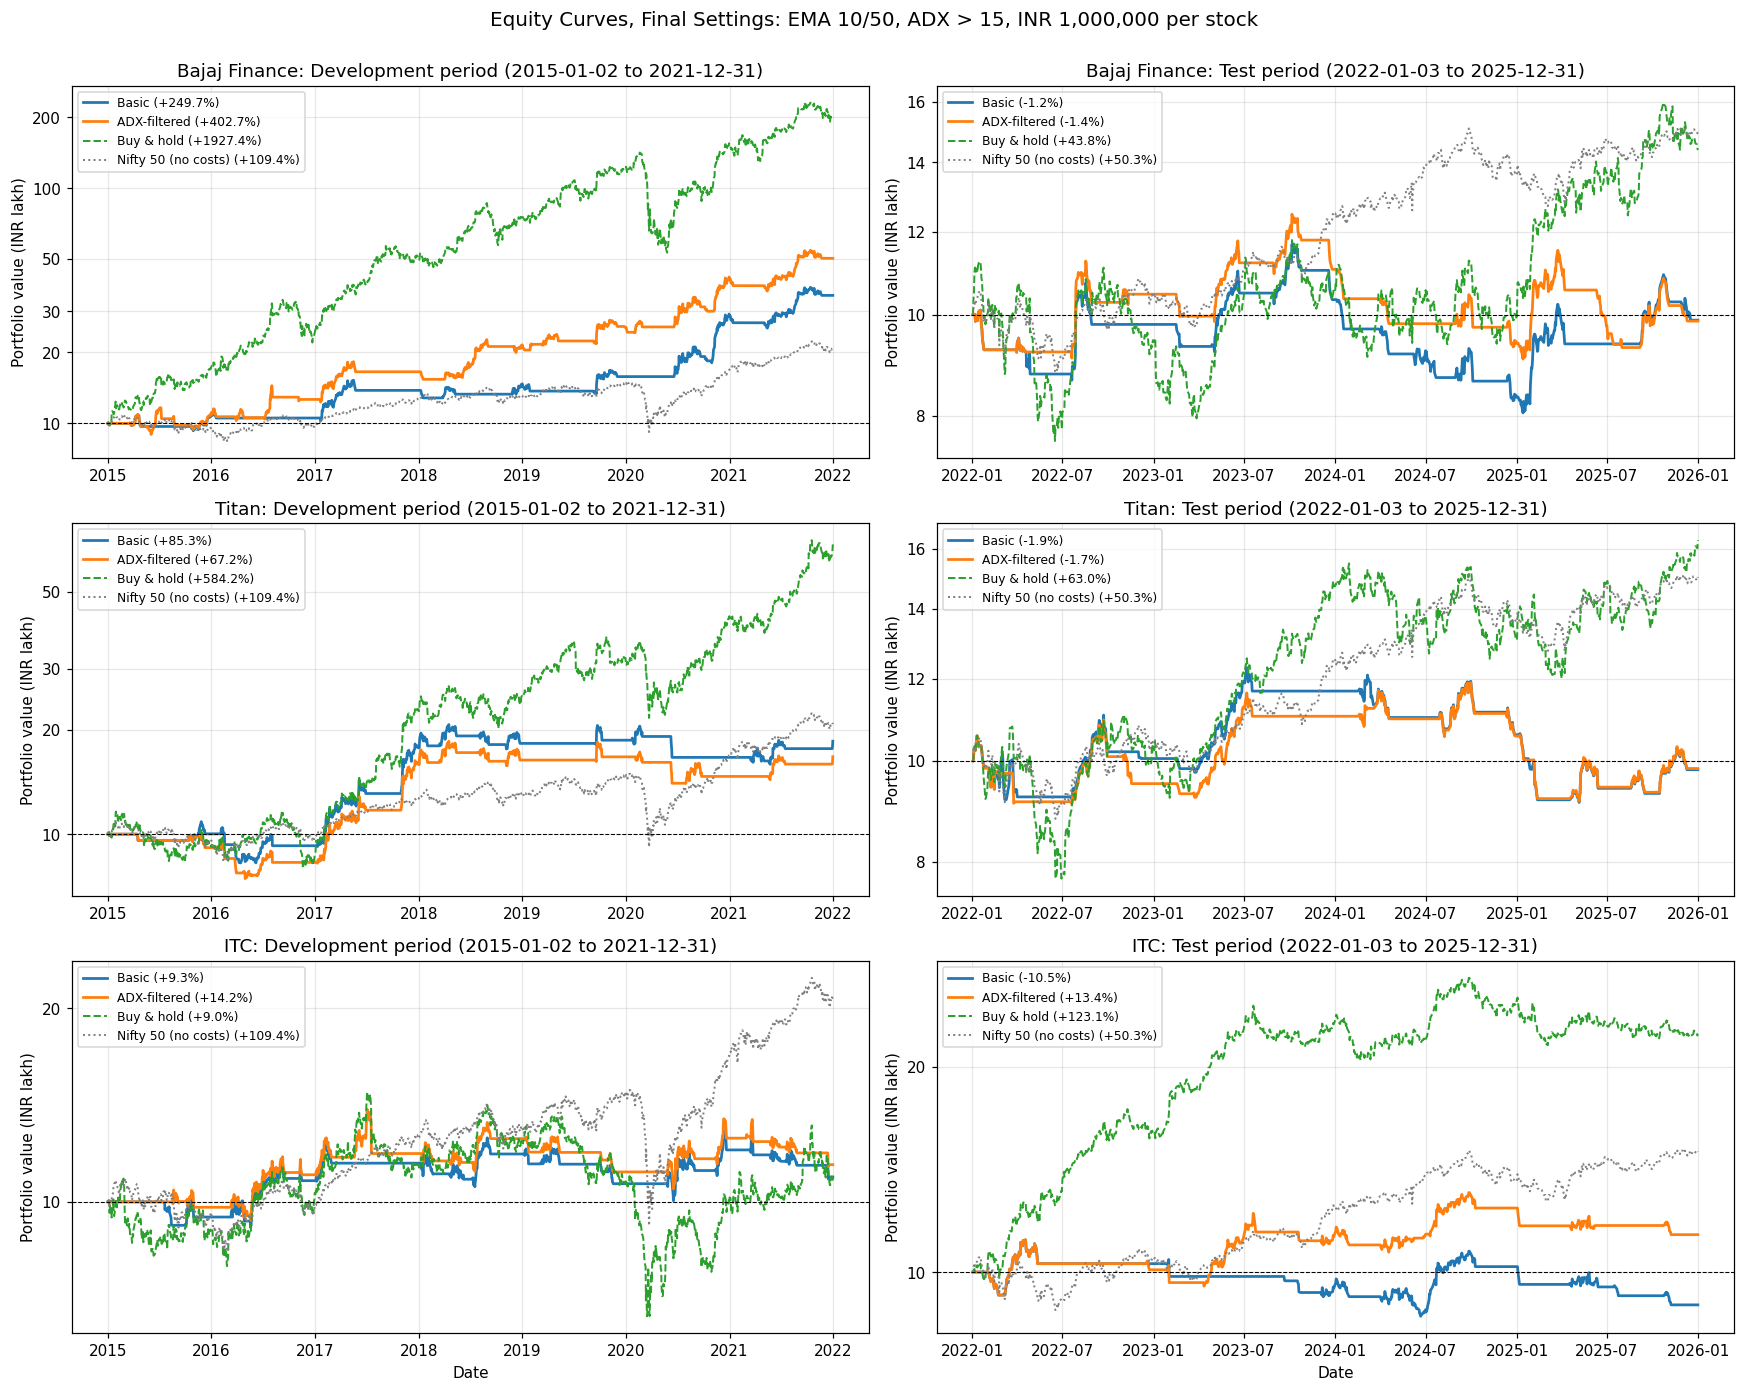

In [ ]:
from matplotlib.ticker import FuncFormatter, LogLocator, NullLocator

LOG_SCALE = True   # True = log y-axis; False = normal axis

stock_names = list(sig_final)
period_names = list(PERIODS_FINAL)
colors = {"Basic": "tab:blue", "ADX-filtered": "tab:orange"}

fig, axes = plt.subplots(len(stock_names), len(period_names),
                         figsize=(8 * len(period_names), 4.2 * len(stock_names)), squeeze=False)

for i, stock in enumerate(stock_names):
    for j, pname in enumerate(period_names):
        ax = axes[i][j]
        curves = {sname: res_f[(pname, stock, sname)]["equity"] for sname in STRATEGIES}
        curves["Buy & hold"] = bh_f[(pname, stock)]
        curves["Nifty 50 (no costs)"] = nifty_f[(pname, stock)]

        for label, eq in curves.items():
            eq0 = with_start(eq)                                   # start every curve from INR 10 lakh
            ret = (eq0.iloc[-1] / eq0.iloc[0] - 1) * 100
            if label in colors:
                ax.plot(eq0.index, eq0 / 1e5, color=colors[label], lw=1.8, label=f"{label} ({ret:+.1f}%)")
            elif label == "Buy & hold":
                ax.plot(eq0.index, eq0 / 1e5, color="tab:green", lw=1.3, ls="--", label=f"{label} ({ret:+.1f}%)")
            else:
                ax.plot(eq0.index, eq0 / 1e5, color="grey", lw=1.3, ls=":", label=f"{label} ({ret:+.1f}%)")

        ax.axhline(INITIAL_CAPITAL / 1e5, color="black", lw=0.7, ls="--")
        first, last = curves["Buy & hold"].index[0].date(), curves["Buy & hold"].index[-1].date()
        ax.set_title(f"{stock}: {pname} period ({first} to {last})")
        ax.set_ylabel("Portfolio value (INR lakh)")
        if LOG_SCALE:
            ax.set_yscale("log")
            ax.yaxis.set_major_locator(LogLocator(base=10, subs=[1, 2, 3, 5], numticks=20))
            ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
            ax.yaxis.set_minor_locator(NullLocator())
        ax.legend(loc="upper left", fontsize=8)
        if i == len(stock_names) - 1:
            ax.set_xlabel("Date")

fig.suptitle(f"Equity Curves, Final Settings: EMA {EMA_FAST_F}/{EMA_SLOW_F}, ADX > {ADX_MIN_F}, "
             f"INR {INITIAL_CAPITAL:,} per stock", y=1.0, fontsize=13)
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "equity_curves_final.png"), dpi=150, bbox_inches="tight")
plt.show()

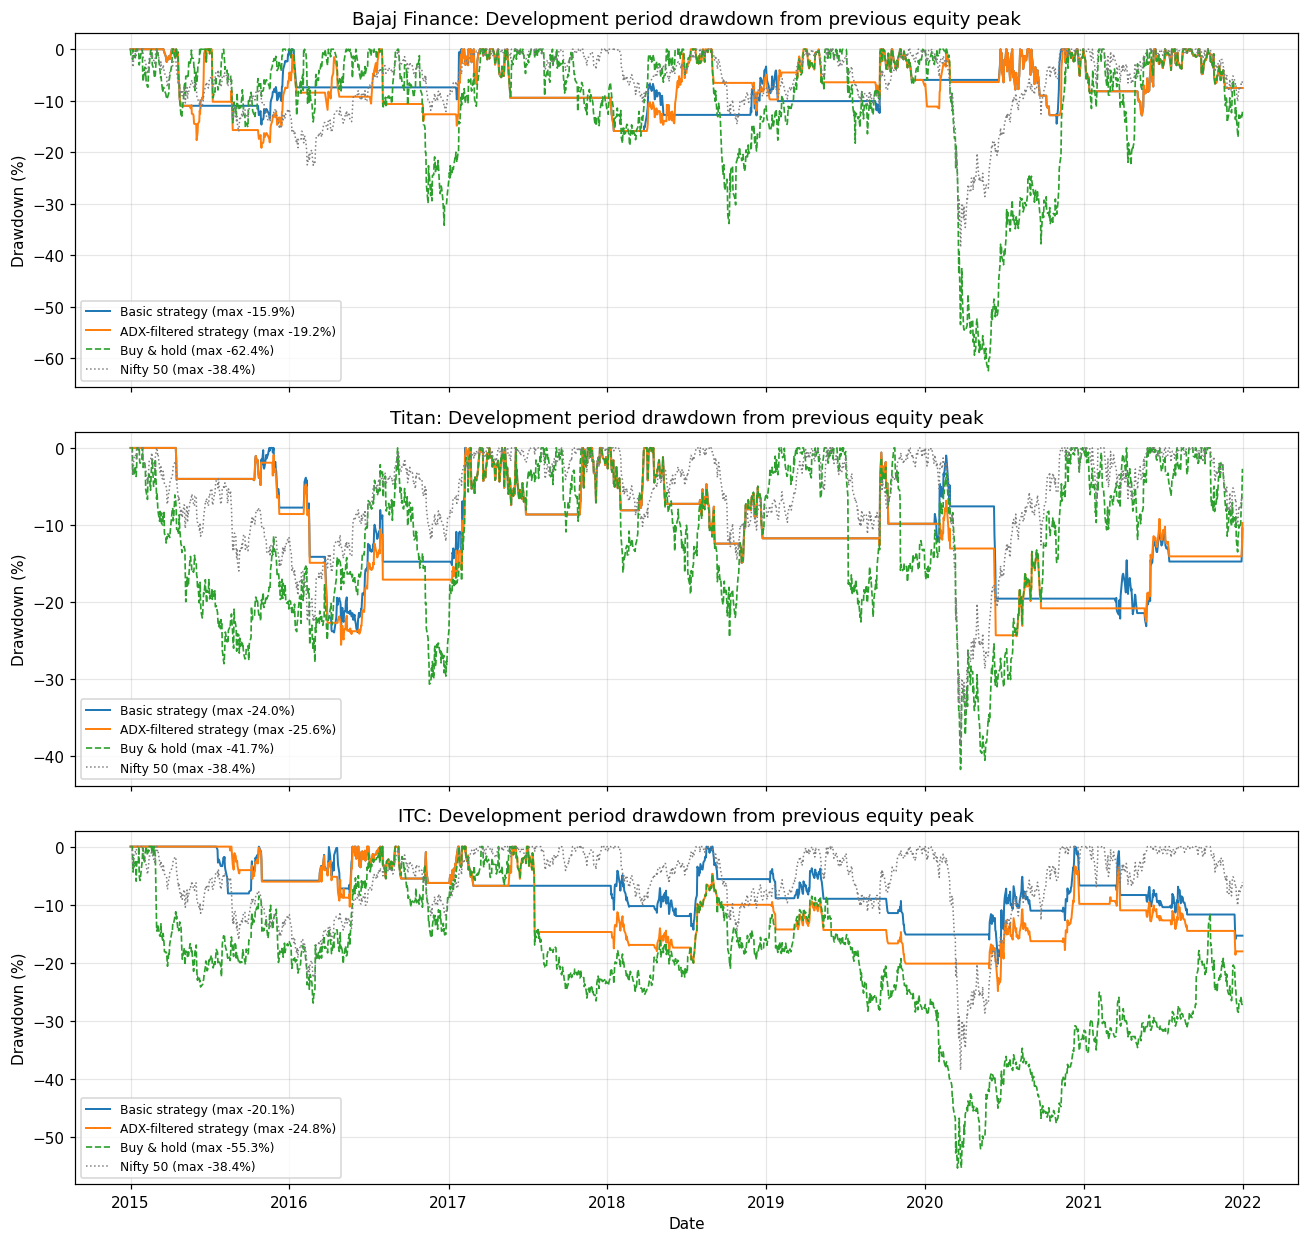

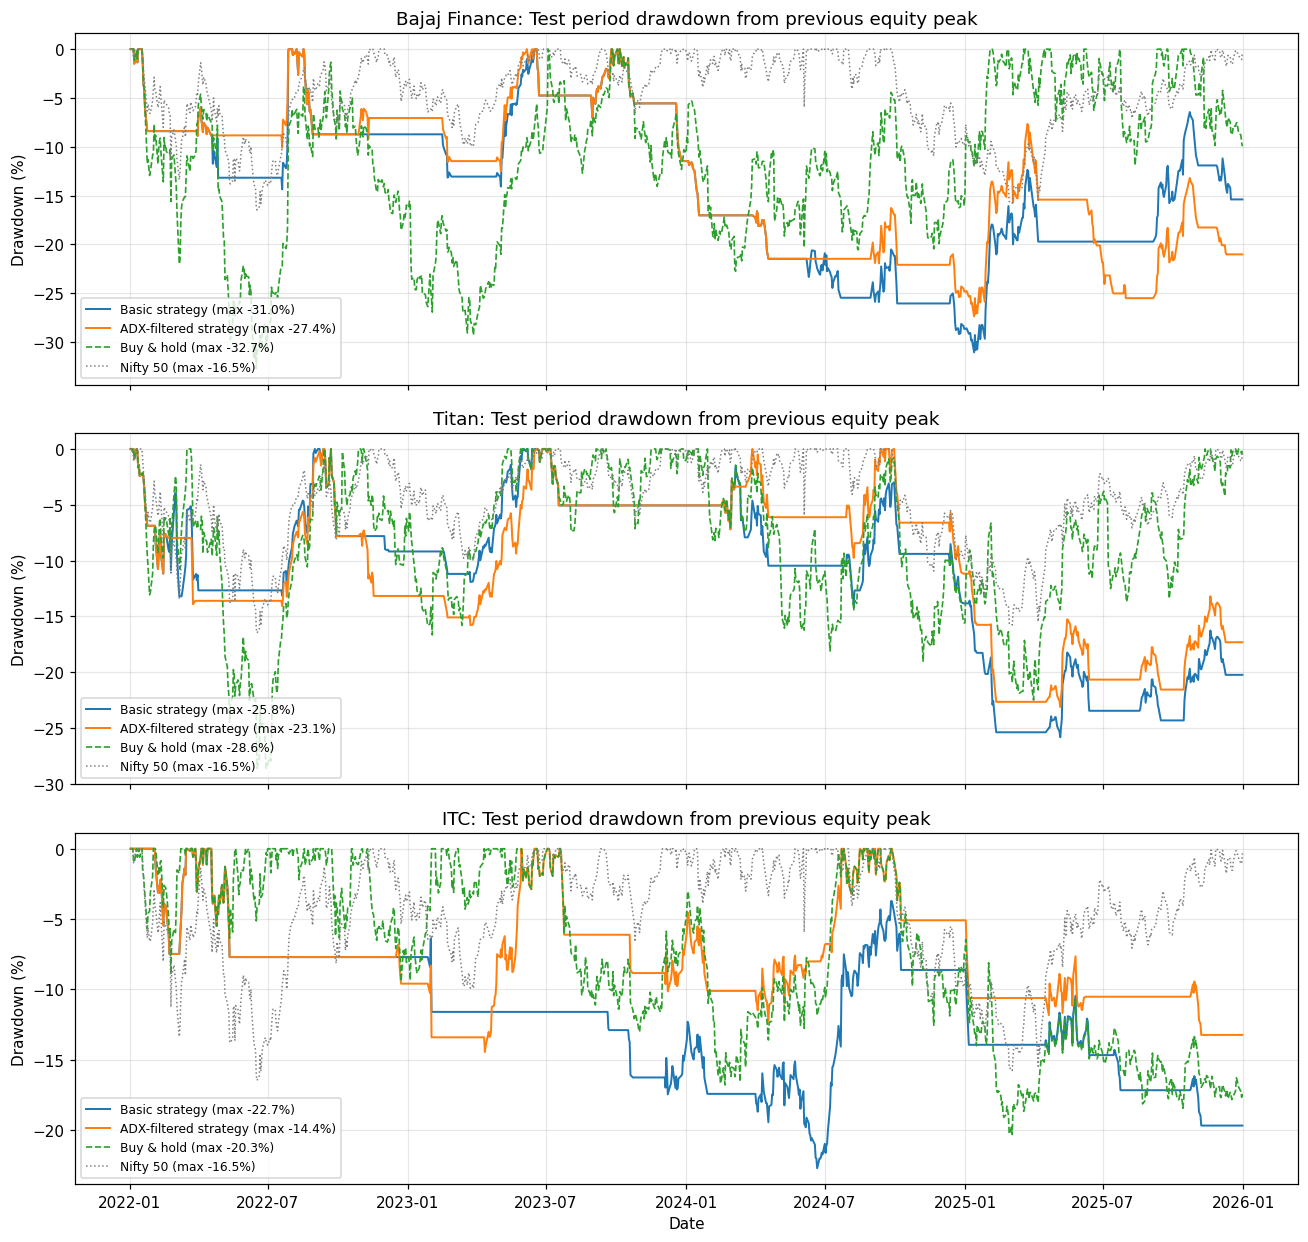

In [ ]:
def dd_pct(eq):
    return (eq / eq.cummax() - 1) * 100

for pname, (s, e) in PERIODS_FINAL.items():
    fig, axes = plt.subplots(len(sig_final), 1, figsize=(12, 3.8 * len(sig_final)), sharex=True)
    for ax, stock in zip(np.atleast_1d(axes), sig_final):
        for sname in STRATEGIES:
            d = dd_pct(with_start(res_f[(pname, stock, sname)]["equity"]))
            ax.plot(d.index, d, lw=1.3, label=f"{sname} strategy (max {d.min():.1f}%)")
        d = dd_pct(with_start(bh_f[(pname, stock)]))
        ax.plot(d.index, d, lw=1.1, ls="--", label=f"Buy & hold (max {d.min():.1f}%)")
        d = dd_pct(with_start(nifty_f[(pname, stock)]))
        ax.plot(d.index, d, lw=1.0, ls=":", color="grey", label=f"Nifty 50 (max {d.min():.1f}%)")
        ax.set_title(f"{stock}: {pname} period drawdown from previous equity peak")
        ax.set_ylabel("Drawdown (%)")
        ax.legend(loc="lower left", fontsize=8)
    np.atleast_1d(axes)[-1].set_xlabel("Date")
    fig.tight_layout()
    fig.savefig(os.path.join(PLOT_DIR, f"drawdown_strategy_{pname.lower()}.png"), dpi=150)
    plt.show()

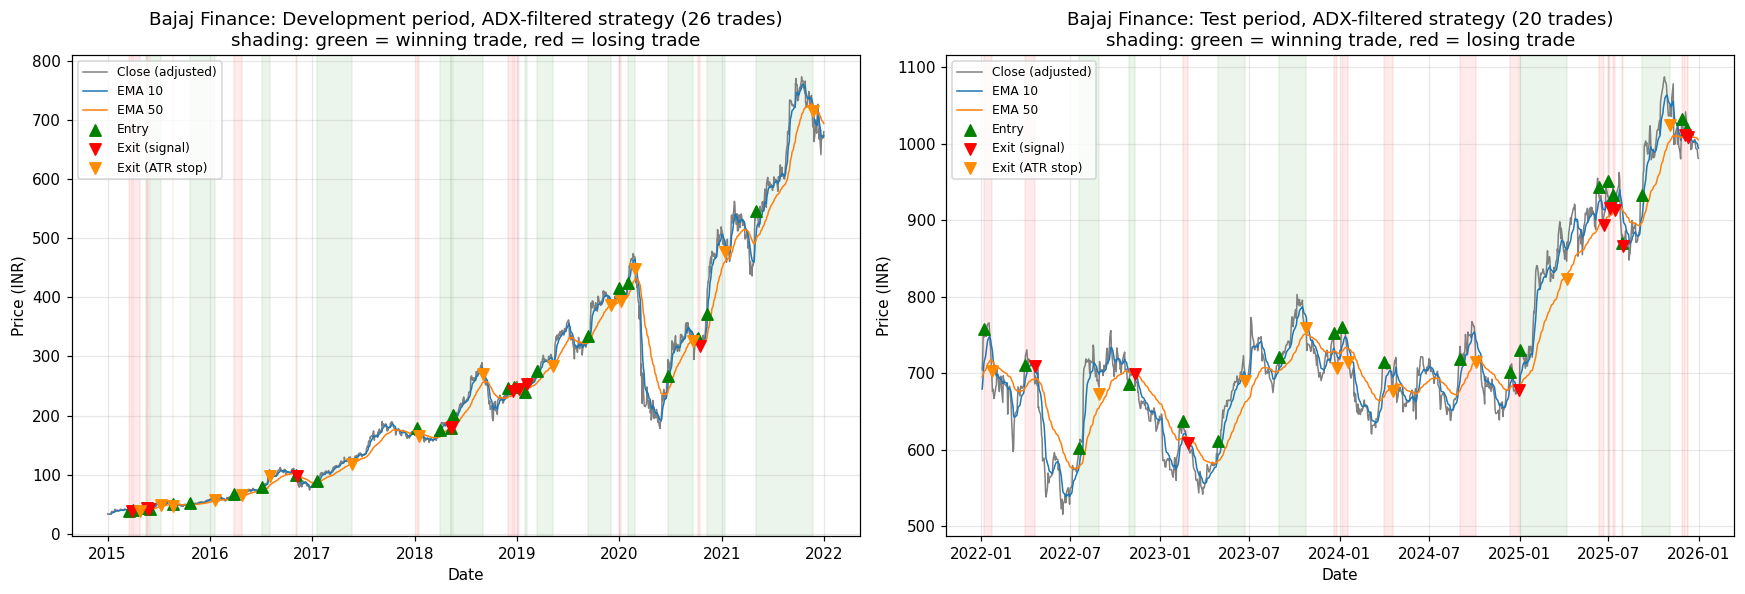

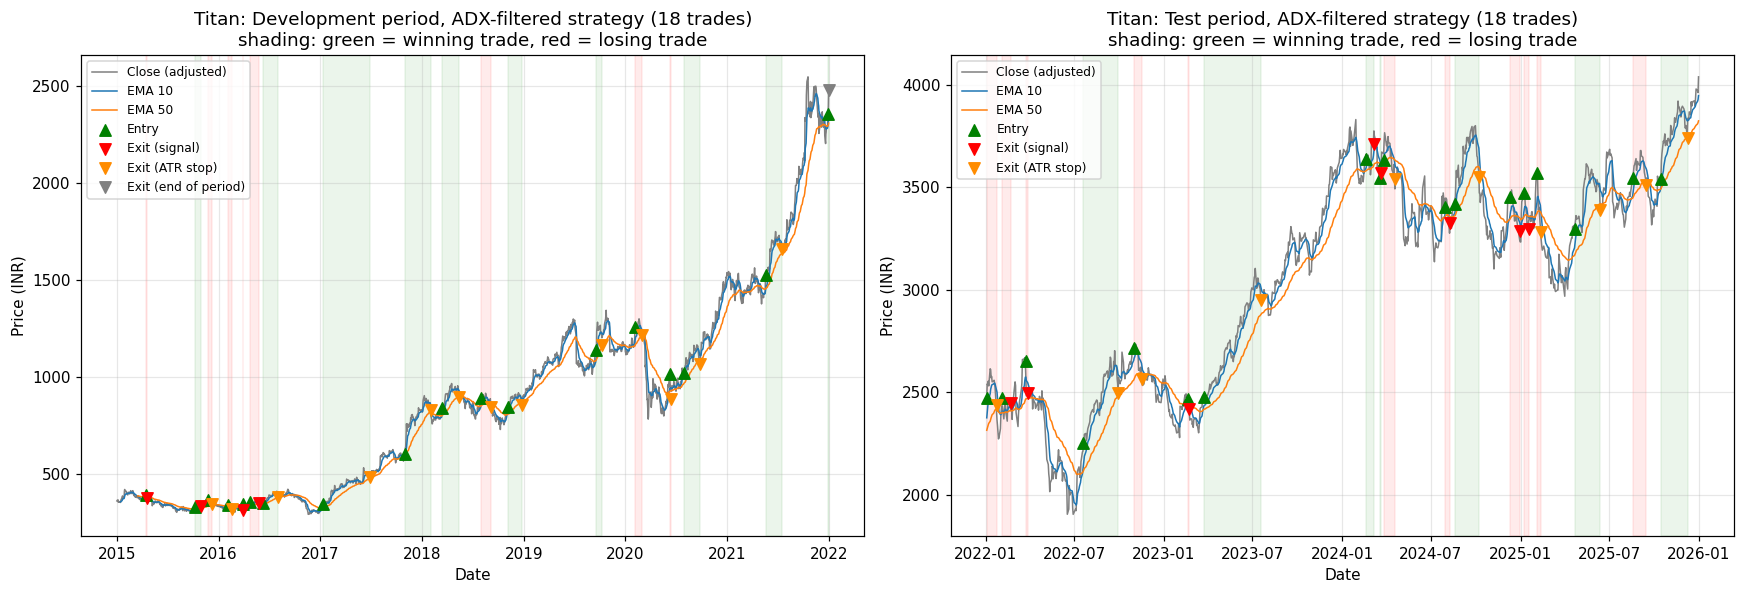

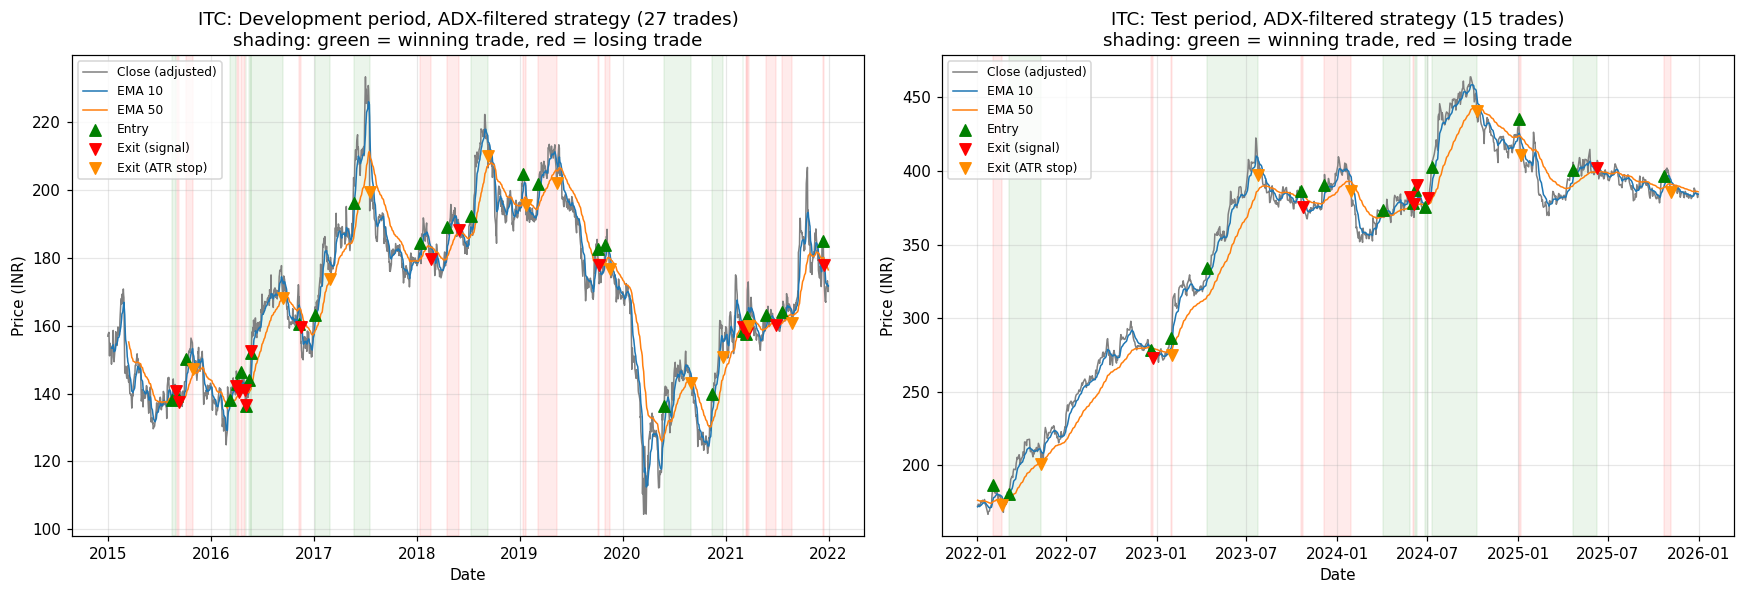

In [ ]:
EXIT_STYLE = {"signal": ("red", "Exit (signal)"), "stop": ("darkorange", "Exit (ATR stop)"),
              "end of period": ("grey", "Exit (end of period)")}

for stock, df in sig_final.items():
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
    for ax, (pname, (s, e)) in zip(axes, PERIODS_FINAL.items()):
        w = df.loc[s:e]
        tr = res_f[(pname, stock, FINAL_STRATEGY)]["trades"]
        ax.plot(w.index, w["Close"], color="grey", lw=1.0, label="Close (adjusted)")
        ax.plot(w.index, w["EMA_fast"], lw=1.0, label=f"EMA {EMA_FAST_F}")
        ax.plot(w.index, w["EMA_slow"], lw=1.0, label=f"EMA {EMA_SLOW_F}")
        for _, t in tr.iterrows():
            ax.axvspan(t["Entry date"], t["Exit date"], color="green" if t["Net P&L (INR)"] > 0 else "red", alpha=0.08)
        if len(tr):
            ax.scatter(tr["Entry date"], tr["Entry price"], marker="^", s=55, color="green", zorder=5, label="Entry")
            for reason, (color, lab) in EXIT_STYLE.items():
                x = tr[tr["Exit reason"] == reason]
                if len(x):
                    ax.scatter(x["Exit date"], x["Exit price"], marker="v", s=55, color=color, zorder=5, label=lab)
        ax.set_title(f"{stock}: {pname} period, {FINAL_STRATEGY} strategy ({len(tr)} trades)\n"
                     f"shading: green = winning trade, red = losing trade")
        ax.set_ylabel("Price (INR)")
        ax.set_xlabel("Date")
        ax.legend(loc="upper left", fontsize=8)
    fig.tight_layout()
    fig.savefig(os.path.join(PLOT_DIR, f"trades_{stock.replace(' ', '_').lower()}.png"), dpi=150)
    plt.show()

In [ ]:
needed = ["sig_final", "res_f", "bh_f", "nifty_f", "PERIODS_FINAL", "STRATEGIES", "FINAL_STRATEGY",
          "with_start", "equity_metrics", "backtest", "add_signals", "clean", "sh",
          "FAST_GRID", "SLOW_GRID", "ADX_GRID", "PAIRS", "EMA_FAST_F", "EMA_SLOW_F", "ADX_MIN_F",
          "show_na", "INITIAL_CAPITAL", "COST_PER_SIDE", "SLIPPAGE_PER_SIDE", "PLOT_DIR", "DATA_DIR"]
missing = [n for n in needed if n not in globals()]
assert not missing, f"Run the earlier cells first. Missing: {missing}"

ANALYSIS_STRATEGIES = list(STRATEGIES)  
REGIME_MA = 200     
REGIME_ADX = 20   
QUICK_DAYS = 10 
LAG_LOOKBACK = 60      
MIN_MOVE_PCT = 5      
COST_MULTIPLIERS = [0, 1, 2]   

print("Strategies analysed:", ANALYSIS_STRATEGIES)
print("Selected setting:", f"EMA {EMA_FAST_F}/{EMA_SLOW_F}, ADX > {ADX_MIN_F}")

Strategies analysed: ['Basic', 'ADX-filtered']
Selected setting: EMA 10/50, ADX > 15


In [ ]:
REGIMES = ["Rising", "Sideways", "Falling"]


def regime_labels(df, adx_level=REGIME_ADX, ma_n=REGIME_MA):
    """Regime of each day as known at the PREVIOUS close."""
    ma = df["Close"].rolling(ma_n).mean()
    adx_ = df["ADX"]
    valid = ma.notna() & adx_.notna()
    lab = pd.Series(np.nan, index=df.index, dtype=object)
    lab[valid & (adx_ <= adx_level)] = "Sideways"
    lab[valid & (adx_ > adx_level) & (df["Close"] > ma)] = "Rising"
    lab[valid & (adx_ > adx_level) & (df["Close"] <= ma)] = "Falling"
    return lab.shift(1)


rows, pool_ret = [], {}
for pname in PERIODS_FINAL:
    for stock in sig_final:
        lab = regime_labels(sig_final[stock])
        curves = {"Buy & hold": bh_f[(pname, stock)]}
        for sname in ANALYSIS_STRATEGIES:
            curves[sname] = res_f[(pname, stock, sname)]["equity"]
        rets = {k: with_start(v).pct_change().dropna() for k, v in curves.items()}
        lab_p = lab.reindex(rets["Buy & hold"].index)

        for reg in REGIMES:
            m = lab_p == reg
            if m.sum() == 0:
                continue
            row = {"Period": pname, "Stock": stock, "Regime": reg, "Days": int(m.sum())}
            for k, r in rets.items():
                rr = r[m]
                row[f"{k} return (%)"] = ((1 + rr).prod() - 1) * 100
                row[f"{k} avg daily (bp)"] = rr.mean() * 1e4
                pool_ret.setdefault((stock, reg, k), []).append(rr.values)
            for sname in ANALYSIS_STRATEGIES:
                inv = res_f[(pname, stock, sname)]["invested"]
                row[f"{sname} invested (%)"] = 100 * inv[m].mean()
            rows.append(row)

regime_tbl = pd.DataFrame(rows).set_index(["Period", "Stock", "Regime"])
ret_cols = ["Days"] + [c for c in regime_tbl.columns if c.endswith("return (%)")]
bp_cols = [c for c in regime_tbl.columns if c.endswith("avg daily (bp)")]
inv_cols = [c for c in regime_tbl.columns if c.endswith("invested (%)")]

print("Compounded return inside each regime:")
display(show_na(regime_tbl[ret_cols], 1))
print("Average daily return inside each regime (basis points):")
display(show_na(regime_tbl[bp_cols], 1))
print("Share of days the strategy was actually invested, per regime:")
display(show_na(regime_tbl[inv_cols], 0))
regime_tbl.to_csv(os.path.join(DATA_DIR, "analysis_regimes.csv"))

Compounded return inside each regime:


Days Buy & hold return (%)  \
Period      Stock         Regime                                 
Development Bajaj Finance Rising    1045                 133.9   
                          Sideways   336                 244.6   
                          Falling    147                  63.5   
            Titan         Rising     969                 240.1   
                          Sideways   335                  88.5   
                          Falling    224                  15.9   
            ITC           Rising     593                  -8.2   
                          Sideways   510                   2.2   
                          Falling    425                  20.1   
Test        Bajaj Finance Rising     424                 -10.3   
                          Sideways   283                   7.9   
                          Falling    281                  48.5   
            Titan         Rising     509                  51.6   
                          Sideways   257                  -4.4   
                          Falling    222                  12.5   
            ITC           Rising     432                  60.8   
                          Sideways   466                  44.4   
                          Falling     90                  -3.9   

                                   Basic return (%) ADX-filtered return (%)  
Period      Stock         Regime                                             
Development Bajaj Finance Rising               56.5                   139.8  
                          Sideways             84.8                    71.2  
                          Falling              24.7                    24.7  
            Titan         Rising               61.7                    54.6  
                          Sideways             16.8                     7.1  
                          Falling               0.9                     3.8  
            ITC           Rising                9.3                     8.1  
                          Sideways              7.2                     9.4  
                          Falling              -4.6                    -4.6  
Test        Bajaj Finance Rising               -3.4                    -3.4  
                          Sideways             -9.9                   -10.1  
                          Falling              13.5                    13.5  
            Titan         Rising               19.2                    19.2  
                          Sideways            -17.1                   -16.9  
                          Falling              -0.8                    -0.8  
            ITC           Rising                5.0                    24.0  
                          Sideways            -10.0                    -3.4  
                          Falling              -5.3                    -5.3

Average daily return inside each regime (basis points):


Buy & hold avg daily (bp)  \
Period      Stock         Regime                               
Development Bajaj Finance Rising                        10.4   
                          Sideways                      39.1   
                          Falling                       45.5   
            Titan         Rising                        14.4   
                          Sideways                      20.9   
                          Falling                       10.6   
            ITC           Rising                        -0.2   
                          Sideways                       1.8   
                          Falling                        6.3   
Test        Bajaj Finance Rising                        -1.2   
                          Sideways                       4.0   
                          Falling                       15.9   
            Titan         Rising                         8.9   
                          Sideways                      -0.5   
                          Falling                        6.7   
            ITC           Rising                        11.7   
                          Sideways                       8.5   
                          Falling                       -3.7   

                                   Basic avg daily (bp)  \
Period      Stock         Regime                          
Development Bajaj Finance Rising                    4.8   
                          Sideways                 19.2   
                          Falling                  16.0   
            Titan         Rising                    5.7   
                          Sideways                  5.7   
                          Falling                   0.7   
            ITC           Rising                    2.0   
                          Sideways                  1.7   
                          Falling                  -0.9   
Test        Bajaj Finance Rising                   -0.2   
                          Sideways                 -3.4   
                          Falling                   4.8   
            Titan         Rising                    3.8   
                          Sideways                 -6.8   
                          Falling                  -0.3   
            ITC           Rising                    1.4   
                          Sideways                 -2.0   
                          Falling                  -5.9   

                                   ADX-filtered avg daily (bp)  
Period      Stock         Regime                                
Development Bajaj Finance Rising                           9.2  
                          Sideways                        17.0  
                          Falling                         16.0  
            Titan         Rising                           5.3  
                          Sideways                         2.8  
                          Falling                          2.0  
            ITC           Rising                           2.0  
                          Sideways                         2.1  
                          Falling                         -0.9  
Test        Bajaj Finance Rising                          -0.2  
                          Sideways                        -3.6  
                          Falling                          4.8  
            Titan         Rising                           3.8  
                          Sideways                        -6.9  
                          Falling                         -0.3  
            ITC           Rising                           5.3  
                          Sideways                        -0.5  
                          Falling                         -5.9

Share of days the strategy was actually invested, per regime:


Basic invested (%)  \
Period      Stock         Regime                        
Development Bajaj Finance Rising                 35.0   
                          Sideways               37.0   
                          Falling                24.0   
            Titan         Rising                 35.0   
                          Sideways               41.0   
                          Falling                11.0   
            ITC           Rising                 47.0   
                          Sideways               23.0   
                          Falling                19.0   
Test        Bajaj Finance Rising                 51.0   
                          Sideways               30.0   
                          Falling                12.0   
            Titan         Rising                 50.0   
                          Sideways               36.0   
                          Falling                14.0   
            ITC           Rising                 27.0   
                          Sideways               29.0   
                          Falling                27.0   

                                   ADX-filtered invested (%)  
Period      Stock         Regime                              
Development Bajaj Finance Rising                        49.0  
                          Sideways                      39.0  
                          Falling                       24.0  
            Titan         Rising                        38.0  
                          Sideways                      21.0  
                          Falling                       12.0  
            ITC           Rising                        53.0  
                          Sideways                      21.0  
                          Falling                       19.0  
Test        Bajaj Finance Rising                        51.0  
                          Sideways                      24.0  
                          Falling                       12.0  
            Titan         Rising                        50.0  
                          Sideways                      28.0  
                          Falling                       14.0  
            ITC           Rising                        43.0  
                          Sideways                      23.0  
                          Falling                       27.0

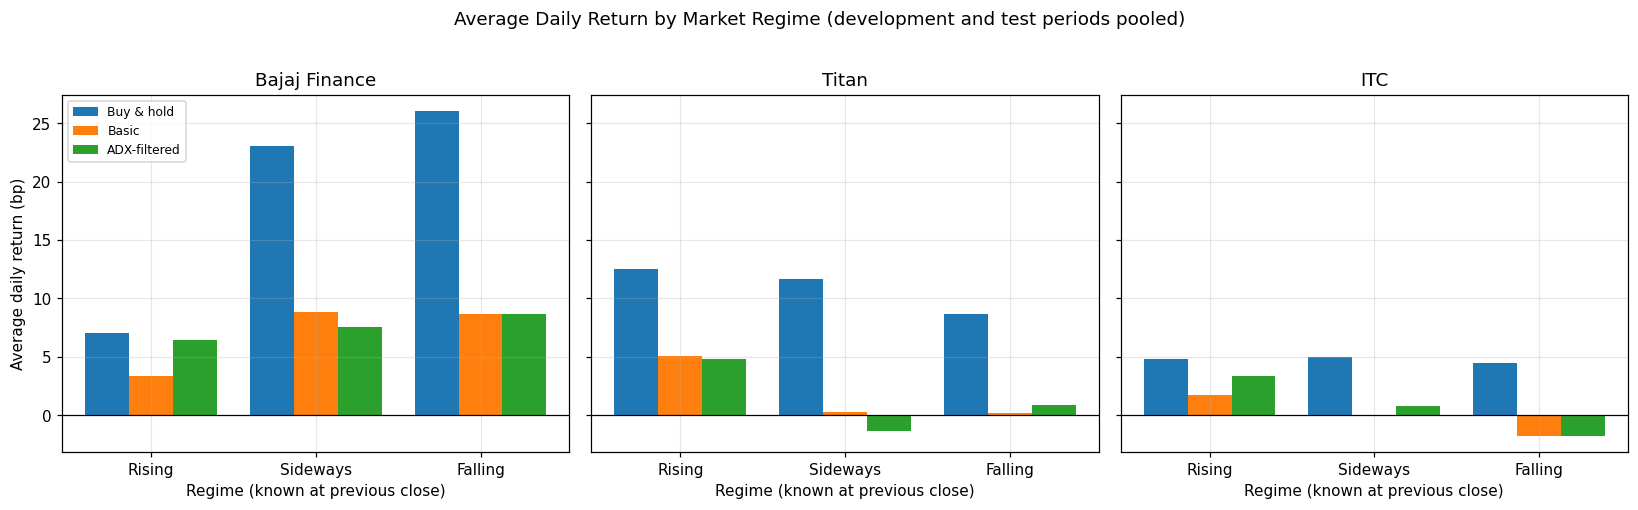

In [ ]:
# Chart: average daily return per regime, both periods pooled
series_names = ["Buy & hold"] + ANALYSIS_STRATEGIES
width = 0.8 / len(series_names)

fig, axes = plt.subplots(1, len(sig_final), figsize=(15, 4.5), sharey=True)
for ax, stock in zip(np.atleast_1d(axes), sig_final):
    for j, k in enumerate(series_names):
        vals = []
        for reg in REGIMES:
            key = (stock, reg, k)
            vals.append(np.mean(np.concatenate(pool_ret[key])) * 1e4 if key in pool_ret else np.nan)
        ax.bar(np.arange(len(REGIMES)) + j * width - 0.4 + width / 2, vals, width=width, label=k)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(range(len(REGIMES)))
    ax.set_xticklabels(REGIMES)
    ax.set_title(stock)
    ax.set_xlabel("Regime (known at previous close)")
np.atleast_1d(axes)[0].set_ylabel("Average daily return (bp)")
np.atleast_1d(axes)[0].legend(fontsize=8)
fig.suptitle("Average Daily Return by Market Regime (development and test periods pooled)", y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "regime_daily_returns.png"), dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
def longest_streak(flags):
    best = cur = 0
    for f in flags:
        cur = cur + 1 if f else 0
        best = max(best, cur)
    return best


rows = []
for (pname, stock, sname), r in res_f.items():
    if len(r["trades"]) == 0:
        continue
    tr = r["trades"].sort_values("Entry date")
    pnl = tr["Net P&L (INR)"]
    win, loss = pnl > 0, pnl < 0
    quick = tr["Holding days"] <= QUICK_DAYS
    stop = tr["Exit reason"] == "stop"
    rows.append({
        "Period": pname, "Stock": stock, "Strategy": sname,
        "Trades": len(tr),
        "Longest losing streak": longest_streak(loss),
        "Avg holding days, winners": tr.loc[win, "Holding days"].mean() if win.any() else np.nan,
        "Avg holding days, losers": tr.loc[loss, "Holding days"].mean() if loss.any() else np.nan,
        f"% trades lasting <= {QUICK_DAYS} days": 100 * quick.mean(),
        f"% trades stopped out within {QUICK_DAYS} days": 100 * (stop & quick).mean(),
        "% trades ended by the stop": 100 * stop.mean(),
    })

whipsaw_tbl = pd.DataFrame(rows).set_index(["Period", "Stock", "Strategy"])
display(show_na(whipsaw_tbl, 1))
whipsaw_tbl.to_csv(os.path.join(DATA_DIR, "analysis_whipsaws.csv"))

Trades Longest losing streak  \
Period      Stock         Strategy                                    
Development Bajaj Finance Basic            12                     2   
                          ADX-filtered     26                     2   
            Titan         Basic            17                     3   
                          ADX-filtered     18                     4   
            ITC           Basic            20                     4   
                          ADX-filtered     27                     5   
Test        Bajaj Finance Basic            15                     6   
                          ADX-filtered     20                     5   
            Titan         Basic            18                     4   
                          ADX-filtered     18                     3   
            ITC           Basic            12                     5   
                          ADX-filtered     15                     2   

                                       Avg holding days, winners  \
Period      Stock         Strategy                                 
Development Bajaj Finance Basic                             96.0   
                          ADX-filtered                      63.9   
            Titan         Basic                             65.8   
                          ADX-filtered                      58.1   
            ITC           Basic                             66.5   
                          ADX-filtered                      42.0   
Test        Bajaj Finance Basic                             60.2   
                          ADX-filtered                      52.5   
            Titan         Basic                             60.8   
                          ADX-filtered                      51.7   
            ITC           Basic                             95.0   
                          ADX-filtered                      53.4   

                                       Avg holding days, losers  \
Period      Stock         Strategy                                
Development Bajaj Finance Basic                            13.2   
                          ADX-filtered                     12.6   
            Titan         Basic                            15.0   
                          ADX-filtered                     15.5   
            ITC           Basic                            24.7   
                          ADX-filtered                     19.9   
Test        Bajaj Finance Basic                            20.2   
                          ADX-filtered                     11.6   
            Titan         Basic                            15.7   
                          ADX-filtered                     14.4   
            ITC           Basic                            22.6   
                          ADX-filtered                     12.6   

                                       % trades lasting <= 10 days  \
Period      Stock         Strategy                                   
Development Bajaj Finance Basic                               16.7   
                          ADX-filtered                        34.6   
            Titan         Basic                               29.4   
                          ADX-filtered                        22.2   
            ITC           Basic                               30.0   
                          ADX-filtered                        40.7   
Test        Bajaj Finance Basic                                6.7   
                          ADX-filtered                        30.0   
            Titan         Basic                               33.3   
                          ADX-filtered                        33.3   
            ITC           Basic                               41.7   
                          ADX-filtered                        46.7   

                                       % trades stopped out within 10 days  \
Period      Stock         Strategy                                           
Development Baj

In [ ]:
def share(part, total):
    return 100 * part / total if total > 0 else np.nan


rows = []
for (pname, stock, sname), r in res_f.items():
    tr = r["trades"]
    if len(tr) == 0:
        continue
    pnl = tr["Net P&L (INR)"]
    order = pnl.sort_values(ascending=False).index
    top1, top3 = list(order[:1]), list(order[:3])
    gross, net = pnl[pnl > 0].sum(), pnl.sum()

    def compounded(drop):
        keep = tr.drop(index=drop)["Return (%)"]
        return ((1 + keep / 100).prod() - 1) * 100

    rows.append({
        "Period": pname, "Stock": stock, "Strategy": sname, "Trades": len(tr),
        "Net profit (INR)": net,
        "Top-1 share of gross profit (%)": share(pnl.loc[top1].sum(), gross),
        "Top-3 share of gross profit (%)": share(pnl.loc[top3].sum(), gross),
        "Top-3 share of net profit (%)": share(pnl.loc[top3].sum(), net),
        "Actual return (%)": (r["equity"].iloc[-1] / INITIAL_CAPITAL - 1) * 100,
        "Return, all trades (%)": compounded([]),
        "Return without top-1 (%)": compounded(top1),
        "Return without top-3 (%)": compounded(top3),
    })

conc_tbl = pd.DataFrame(rows).set_index(["Period", "Stock", "Strategy"])
display(show_na(conc_tbl, 1))
conc_tbl.to_csv(os.path.join(DATA_DIR, "analysis_profit_concentration.csv"))

Trades Net profit (INR)  \
Period      Stock         Strategy                               
Development Bajaj Finance Basic            12        2497451.5   
                          ADX-filtered     26        4026847.6   
            Titan         Basic            17         853109.2   
                          ADX-filtered     18         672171.0   
            ITC           Basic            20          92880.0   
                          ADX-filtered     27         142288.7   
Test        Bajaj Finance Basic            15         -12342.4   
                          ADX-filtered     20         -14357.5   
            Titan         Basic            18         -19377.2   
                          ADX-filtered     18         -16818.8   
            ITC           Basic            12        -104896.7   
                          ADX-filtered     15         134403.7   

                                       Top-1 share of gross profit (%)  \
Period      Stock         Strategy                                       
Development Bajaj Finance Basic                                   30.8   
                          ADX-filtered                            25.3   
            Titan         Basic                                   33.3   
                          ADX-filtered                            33.7   
            ITC           Basic                                   31.3   
                          ADX-filtered                            19.4   
Test        Bajaj Finance Basic                                   24.9   
                          ADX-filtered                            24.2   
            Titan         Basic                                   45.9   
                          ADX-filtered                            42.5   
            ITC           Basic                                   54.1   
                          ADX-filtered                            41.5   

                                       Top-3 share of gross profit (%)  \
Period      Stock         Strategy                                       
Development Bajaj Finance Basic                                   73.8   
                          ADX-filtered                            55.5   
            Titan         Basic                                   69.1   
                          ADX-filtered                            69.8   
            ITC           Basic                                   69.7   
                          ADX-filtered                            54.9   
Test        Bajaj Finance Basic                                   69.0   
                          ADX-filtered                            67.6   
            Titan         Basic                                   82.7   
                          ADX-filtered                            78.3   
            ITC           Basic                                   96.4   
                          ADX-filtered                            89.5   

                                       Top-3 share of net profit (%)  \
Period      Stock         Strategy                                     
Development Bajaj Finance Basic                                 80.0   
                          ADX-filtered                          64.3   
            Titan         Basic                                118.3   
                          ADX-filtered                         134.6   
            ITC           Basic                                368.1   
                          ADX-filtered                         208.8   
Test        Bajaj Finance Basic                                  N/A   
                          ADX-filtered                           N/A   
            Titan         Basic                                  N/A   
                          ADX-filtered                           N/A   
            ITC           Basic                                  N/A   
                          ADX-filtered                         288.2   

                               

In [ ]:
detail = []
for (pname, stock, sname), r in res_f.items():
    tr = r["trades"]
    if len(tr) == 0:
        continue
    close = sig_final[stock]["Close"]
    idx = close.index
    for _, t in tr.iterrows():
        ei, xi = idx.get_loc(t["Entry date"]), idx.get_loc(t["Exit date"])
        lo = max(ei - LAG_LOOKBACK, 0)
        if ei - lo < 5:
            continue
        pre = close.iloc[lo:ei]                         # closes known before the entry day
        trough_pos = lo + int(np.argmin(pre.to_numpy()))
        trough = close.iloc[trough_pos]
        peak = close.iloc[trough_pos:xi + 1].max()
        move = peak - trough
        if trough <= 0 or 100 * move / trough < MIN_MOVE_PCT:
            continue
        entry_px, exit_px = t["Entry price"], t["Exit price"]
        detail.append({
            "Period": pname, "Stock": stock, "Strategy": sname,
            "Days from low to entry": (idx[ei] - idx[trough_pos]).days,
            "Already gone at entry (% of move)": 100 * (entry_px - trough) / move,
            "Captured (% of move)": 100 * (exit_px - entry_px) / move,
            "Given back at exit (% of move)": 100 * (peak - exit_px) / move,
        })

lag_detail = pd.DataFrame(detail)
lag_cols = ["Days from low to entry", "Already gone at entry (% of move)",
            "Captured (% of move)", "Given back at exit (% of move)"]
lag_tbl = lag_detail.groupby(["Period", "Stock", "Strategy"])[lag_cols].median()
lag_tbl.insert(0, "Trades used", lag_detail.groupby(["Period", "Stock", "Strategy"]).size())
print("Median values per group:")
display(show_na(lag_tbl, 1))
lag_tbl.to_csv(os.path.join(DATA_DIR, "analysis_signal_lag.csv"))



Median values per group:


Trades used Days from low to entry  \
Period      Stock         Strategy                                          
Development Bajaj Finance ADX-filtered          26                   56.5   
                          Basic                 12                   34.0   
            ITC           ADX-filtered          27                   53.0   
                          Basic                 20                   40.0   
            Titan         ADX-filtered          18                   54.0   
                          Basic                 17                   42.0   
Test        Bajaj Finance ADX-filtered          20                   32.5   
                          Basic                 15                   26.0   
            ITC           ADX-filtered          14                   45.5   
                          Basic                  9                   41.0   
            Titan         ADX-filtered          18                   46.5   
                          Basic                 18                   48.0   

                                       Already gone at entry (% of move)  \
Period      Stock         Strategy                                         
Development Bajaj Finance ADX-filtered                              59.5   
                          Basic                                     47.0   
            ITC           ADX-filtered                              63.3   
                          Basic                                     63.6   
            Titan         ADX-filtered                              59.4   
                          Basic                                     49.5   
Test        Bajaj Finance ADX-filtered                              75.9   
                          Basic                                     85.4   
            ITC           ADX-filtered                              63.0   
                          Basic                                     63.2   
            Titan         ADX-filtered                              64.6   
                          Basic                                     61.7   

                                       Captured (% of move)  \
Period      Stock         Strategy                            
Development Bajaj Finance ADX-filtered                  7.0   
                          Basic                        25.8   
            ITC           ADX-filtered                 -3.1   
                          Basic                       -11.0   
            Titan         ADX-filtered                  7.0   
                          Basic                         9.7   
Test        Bajaj Finance ADX-filtered                 -9.2   
                          Basic                       -26.8   
            ITC           ADX-filtered                  0.6   
                          Basic                       -27.1   
            Titan         ADX-filtered                 -7.8   
                          Basic                       -16.5   

                                       Given back at exit (% of move)  
Period      Stock         Strategy                                     
Development Bajaj Finance ADX-filtered                           27.2  
                          Basic                                  28.8  
            ITC           ADX-filtered                           42.5  
                          Basic                                  47.1  
            Titan         ADX-filtered                           33.4  
                          Basic                                  42.6  
Test        Bajaj Finance ADX-filtered                           40.9  
                          Basic                                  41.4  
            ITC           ADX-filtered                           33.0  
                          Basic                                  59.9  
            Titan         ADX-filtered                           42.0  
                          Basic                                  44.8

Selected setting: Sharpe ratio, development vs test


,"Dev Sharpe, selected","Test Sharpe, selected","Dev Sharpe, same EMA no ADX","Test Sharpe, same EMA no ADX","Dev Sharpe, buy & hold","Test Sharpe, buy & hold"
Stock,,,,,,
Bajaj Finance,0.95,-0.36,0.79,-0.34,1.17,0.26
Titan,0.18,-0.47,0.26,-0.42,0.84,0.4
ITC,-0.21,-0.16,-0.3,-0.73,-0.03,0.89
Mean of 3 stocks,0.31,-0.33,0.25,-0.5,0.66,0.52



The selected setting and its 7 neighbours:


,Dev Sharpe (mean of 3),Test Sharpe (mean of 3),"Test Sharpe, Bajaj Finance","Test Sharpe, Titan","Test Sharpe, ITC"
Setting,,,,,
"EMA 10/50, ADX > 15 (selected)",0.31,-0.33,-0.36,-0.47,-0.16
"EMA 10/50, ADX > 20",0.2,-0.08,-0.32,-0.15,0.22
"EMA 10/100, ADX > 15",0.12,-0.52,-0.84,-0.58,-0.14
"EMA 10/100, ADX > 20",0.14,-0.17,-0.7,-0.04,0.21
"EMA 20/50, ADX > 15",0.21,-0.24,-0.37,-0.4,0.05
"EMA 20/50, ADX > 20",0.14,-0.07,-0.28,-0.04,0.11
"EMA 20/100, ADX > 15",0.09,-0.65,-1.08,-0.67,-0.21
"EMA 20/100, ADX > 20",0.1,-0.2,-0.75,0.06,0.09


Neighbours' test Sharpe: mean -0.28, min -0.65, max -0.07, 0% positive

Rank correlation (development vs test Sharpe) over 45 settings: 0.21
The selected setting ranked 1 of 45 in development and 29 of 45 in the test period.
Share of all 45 settings with a positive test Sharpe: 7%


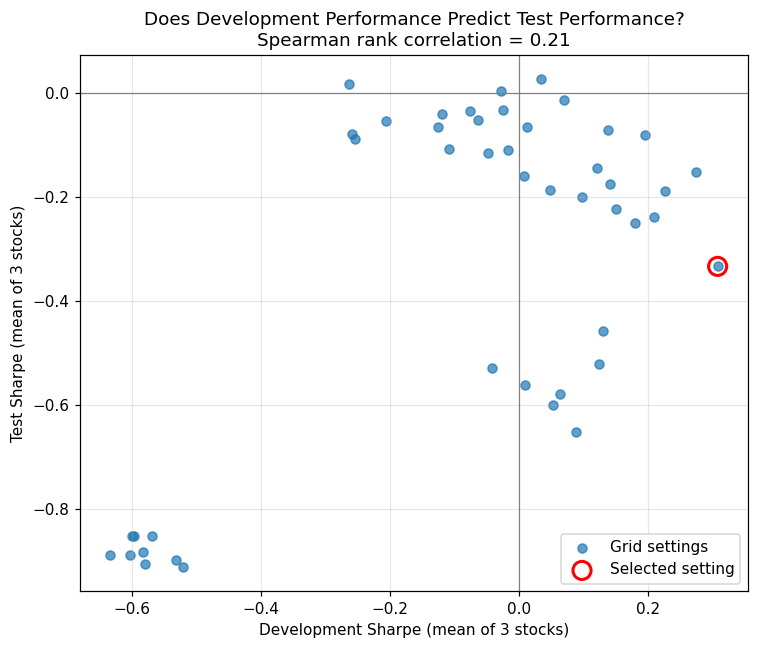

In [ ]:
test_s, test_e = PERIODS_FINAL["Test"]

sh_test = {}      # (fast, slow, column, stock) -> test-period Sharpe, same grid as development
for fast, slow in PAIRS:
    for stock, base in clean.items():
        d0 = add_signals(base, ema_fast=fast, ema_slow=slow)
        r0 = backtest(d0, "target_basic", test_s, test_e)
        sh_test[(fast, slow, "Basic", stock)] = equity_metrics(with_start(r0["equity"]))["Sharpe"]
        for a in ADX_GRID:
            d = add_signals(base, ema_fast=fast, ema_slow=slow, adx_min=a)
            r = backtest(d, "target_adx", test_s, test_e)
            sh_test[(fast, slow, a, stock)] = equity_metrics(with_start(r["equity"]))["Sharpe"]

# --- 1) selected setting, development vs test ---
rows = []
for stock in clean:
    rows.append({
        "Stock": stock,
        "Dev Sharpe, selected": sh[(EMA_FAST_F, EMA_SLOW_F, ADX_MIN_F, stock)],
        "Test Sharpe, selected": sh_test[(EMA_FAST_F, EMA_SLOW_F, ADX_MIN_F, stock)],
        "Dev Sharpe, same EMA no ADX": sh[(EMA_FAST_F, EMA_SLOW_F, "Basic", stock)],
        "Test Sharpe, same EMA no ADX": sh_test[(EMA_FAST_F, EMA_SLOW_F, "Basic", stock)],
        "Dev Sharpe, buy & hold": equity_metrics(with_start(bh_f[("Development", stock)]))["Sharpe"],
        "Test Sharpe, buy & hold": equity_metrics(with_start(bh_f[("Test", stock)]))["Sharpe"],
    })
stab_sel = pd.DataFrame(rows).set_index("Stock")
stab_sel.loc["Mean of 3 stocks"] = stab_sel.mean()
print("Selected setting: Sharpe ratio, development vs test")
display(show_na(stab_sel, 2))

# --- 2) neighbours of the selected setting ---
bi, bj, bk = FAST_GRID.index(EMA_FAST_F), SLOW_GRID.index(EMA_SLOW_F), ADX_GRID.index(ADX_MIN_F)
neigh = [(FAST_GRID[i], SLOW_GRID[j], ADX_GRID[k])
         for i in range(max(bi - 1, 0), min(bi + 2, len(FAST_GRID)))
         for j in range(max(bj - 1, 0), min(bj + 2, len(SLOW_GRID)))
         for k in range(max(bk - 1, 0), min(bk + 2, len(ADX_GRID)))]

rows = []
for f, s, a in neigh:
    row = {"Setting": f"EMA {f}/{s}, ADX > {a}" + ("  (selected)" if (f, s, a) == (EMA_FAST_F, EMA_SLOW_F, ADX_MIN_F) else ""),
           "Dev Sharpe (mean of 3)": np.nanmean([sh[(f, s, a, st)] for st in clean]),
           "Test Sharpe (mean of 3)": np.nanmean([sh_test[(f, s, a, st)] for st in clean])}
    for st in clean:
        row[f"Test Sharpe, {st}"] = sh_test[(f, s, a, st)]
    rows.append(row)
stab_neigh = pd.DataFrame(rows).set_index("Setting")
print(f"\nThe selected setting and its {len(neigh) - 1} neighbours:")
display(show_na(stab_neigh, 2))
tn = stab_neigh["Test Sharpe (mean of 3)"]
print(f"Neighbours' test Sharpe: mean {tn.mean():.2f}, min {tn.min():.2f}, max {tn.max():.2f}, "
      f"{100 * (tn > 0).mean():.0f}% positive")

# --- 3) rank correlation across the whole ADX-filtered grid ---
cells_all = [(f, s, a) for f, s in PAIRS for a in ADX_GRID]
dev_vec = pd.Series([np.nanmean([sh[(f, s, a, st)] for st in clean]) for f, s, a in cells_all], index=cells_all)
test_vec = pd.Series([np.nanmean([sh_test[(f, s, a, st)] for st in clean]) for f, s, a in cells_all], index=cells_all)
rho = dev_vec.rank().corr(test_vec.rank())
sel_key = (EMA_FAST_F, EMA_SLOW_F, ADX_MIN_F)
sel_dev_rank = int(dev_vec.rank(ascending=False)[sel_key])
sel_test_rank = int(test_vec.rank(ascending=False)[sel_key])
print(f"\nRank correlation (development vs test Sharpe) over {len(cells_all)} settings: {rho:.2f}")
print(f"The selected setting ranked {sel_dev_rank} of {len(cells_all)} in development and {sel_test_rank} of {len(cells_all)} in the test period.")
print(f"Share of all {len(cells_all)} settings with a positive test Sharpe: {100 * (test_vec > 0).mean():.0f}%")

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(dev_vec, test_vec, s=35, alpha=0.7, label="Grid settings")
ax.scatter([dev_vec[sel_key]], [test_vec[sel_key]], s=140, facecolors="none", edgecolors="red", lw=2, label="Selected setting")
ax.axhline(0, color="grey", lw=0.8)
ax.axvline(0, color="grey", lw=0.8)
ax.set_xlabel("Development Sharpe (mean of 3 stocks)")
ax.set_ylabel("Test Sharpe (mean of 3 stocks)")
ax.set_title(f"Does Development Performance Predict Test Performance?\nSpearman rank correlation = {rho:.2f}")
ax.legend()
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "stability_dev_vs_test.png"), dpi=150)
plt.show()

stab_sel.to_csv(os.path.join(DATA_DIR, "analysis_stability_selected.csv"))
stab_neigh.to_csv(os.path.join(DATA_DIR, "analysis_stability_neighbours.csv"))

In [ ]:
rows = []
for pname, (s, e) in PERIODS_FINAL.items():
    for stock, df in sig_final.items():
        for sname, col in STRATEGIES.items():
            row = {"Period": pname, "Stock": stock, "Strategy": sname}
            for mult in COST_MULTIPLIERS:
                cost, slip = COST_PER_SIDE * mult, SLIPPAGE_PER_SIDE * mult
                label = f"{100 * (cost + slip):.2f}%"
                r = backtest(df, col, s, e, cost=cost, slip=slip)
                m = equity_metrics(with_start(r["equity"]))
                row[f"Return @ {label} (%)"] = m["Cumulative return (%)"]
                row[f"Sharpe @ {label}"] = m["Sharpe"]
                if mult == max(COST_MULTIPLIERS):
                    t = r["trades"]
                    row["Trades"] = len(t)
                    row[f"Costs + slippage paid @ {label} (INR)"] = (t["Fees (INR)"] + t["Slippage (INR)"]).sum() if len(t) else 0.0
                if mult == 1:   # baseline: must match the main run exactly
                    base = equity_metrics(with_start(res_f[(pname, stock, sname)]["equity"]))
                    assert np.isclose(m["Cumulative return (%)"], base["Cumulative return (%)"], atol=1e-9), \
                        f"Baseline mismatch: {pname}/{stock}/{sname}"
            ret_cols_c = [c for c in row if c.startswith("Return @")]
            row["Return lost to costs, 0% to 0.30% (pp)"] = row[ret_cols_c[0]] - row[ret_cols_c[-1]]
            rows.append(row)

cost_tbl = pd.DataFrame(rows).set_index(["Period", "Stock", "Strategy"])
print("Baseline check passed: the 0.15% run matches the main results.\n")
display(show_na(cost_tbl, 2))
cost_tbl.to_csv(os.path.join(DATA_DIR, "analysis_cost_sensitivity.csv"))

Baseline check passed: the 0.15% run matches the main results.



Return @ 0.00% (%) Sharpe @ 0.00%  \
Period      Stock         Strategy                                         
Development Bajaj Finance Basic                    262.56           0.83   
                          ADX-filtered             443.46           1.01   
            Titan         Basic                     95.02            0.3   
                          ADX-filtered              76.51           0.22   
            ITC           Basic                     16.04          -0.23   
                          ADX-filtered              23.87          -0.13   
Test        Bajaj Finance Basic                       3.3          -0.27   
                          ADX-filtered               4.68          -0.26   
            Titan         Basic                      3.46          -0.32   
                          ADX-filtered               3.75          -0.36   
            ITC           Basic                     -7.21          -0.66   
                          ADX-filtered              18.66          -0.07   

                                       Return @ 0.15% (%) Sharpe @ 0.15%  \
Period      Stock         Strategy                                         
Development Bajaj Finance Basic                    249.75           0.79   
                          ADX-filtered             402.68           0.95   
            Titan         Basic                     85.31           0.26   
                          ADX-filtered              67.22           0.18   
            ITC           Basic                      9.29           -0.3   
                          ADX-filtered              14.23          -0.21   
Test        Bajaj Finance Basic                     -1.23          -0.34   
                          ADX-filtered              -1.44          -0.36   
            Titan         Basic                     -1.94          -0.42   
                          ADX-filtered              -1.68          -0.47   
            ITC           Basic                    -10.49          -0.73   
                          ADX-filtered              13.44          -0.16   

                                       Return @ 0.30% (%) Sharpe @ 0.30%  \
Period      Stock         Strategy                                         
Development Bajaj Finance Basic                    237.37           0.76   
                          ADX-filtered             364.94            0.9   
            Titan         Basic                     76.11           0.22   
                          ADX-filtered              58.42           0.14   
            ITC           Basic                      2.92          -0.36   
                          ADX-filtered               5.34          -0.29   
Test        Bajaj Finance Basic                     -5.57          -0.42   
                          ADX-filtered              -7.17          -0.46   
            Titan         Basic                     -7.08          -0.53   
                          ADX-filtered              -6.85          -0.59   
            ITC           Basic                    -13.65          -0.81   
                          ADX-filtered               8.45          -0.26   

                                       Trades  \
Period      Stock         Strategy              
Development Bajaj Finance Basic            12   
                          ADX-filtered     26   
            Titan         Basic            17   
                          ADX-filtered     18   
            ITC           Basic            20   
                          ADX-filtered     27   
Test        Bajaj Finance Basic            15   
                          ADX-filtered     20   
            Titan         Basic            18   
                          ADX-filtered     18   
            ITC           Basic            12   
                          ADX-filtered     15   

                                       Costs + slippage paid @ 0.30% (INR)  \
Period      Stock         Strategy                                           
D